# Usage of CHIC python module

Brief overview of how to run CHIC to compute neutrino oscillation probabilities and their derivatives.
It assumes that CHIC python bindings have been compiled.

First we import the necessary modules including pychic.

In [128]:
import pychic
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams.update({
    # Figure
    'figure.figsize'        : (5, 5),
    'savefig.dpi'           : 600,

    # Font
    'font.size'             : 14,
    'font.family'           : 'serif',
    'font.serif'            : ['Computer Modern', 'Latin Modern Roman', 'Bitstream Vera Serif'],
    'text.usetex'           : True,

    # Axes
    'axes.grid'             : False,
    'image.cmap'            : 'plasma',

    # Lines & patches
    'lines.linewidth'       : 2,
    'patch.linewidth'       : 2,

    # Tick labels
    'xtick.labelsize'       : 'medium',
    'ytick.labelsize'       : 'medium',

    # Minor ticks visibility
    'xtick.minor.visible'   : True,
    'ytick.minor.visible'   : True,

    # Tick sizes
    'xtick.major.size'      : 5,
    'xtick.minor.size'      : 2,
    'ytick.major.size'      : 5,
    'ytick.minor.size'      : 2,

    # Tick widths
    'xtick.major.width'     : 1,
    'xtick.minor.width'     : 1,
    'ytick.major.width'     : 1,
    'ytick.minor.width'     : 1,

    # Legend
    'legend.frameon'        : False,
    'legend.fontsize'       : 12,
})


As we are dealing with constant density media, we will restrict this example to long-basline neutrino experiments such as DUNE or HyperK/T2K. For this example we will focus on the three HK detectors for accelerator neutrinos, ND280 at 280 m, IWCD at 1 km, and HK-FD at 295 km from the target.

In [129]:
detectors = {"ND280": 0.280, "IWCD": 1., "HK-FD": 295.} # detectors and baselines

As for the neutrino energy, we will assume for most of the examples just the peak of the spectrum at 0.6 GeV. However, for the sake of the first illustration plots we will also compute the oscillation probabilities at different energies.

In [130]:
Enu_peak = 0.6 # GeV
Enu = np.linspace(0.1, 1.2, 100)

## Oscillation probabilities
As a first example we will compute the disappearance and appearance oscillation probbailities for all detectors as a function of energy and for neutrinos.

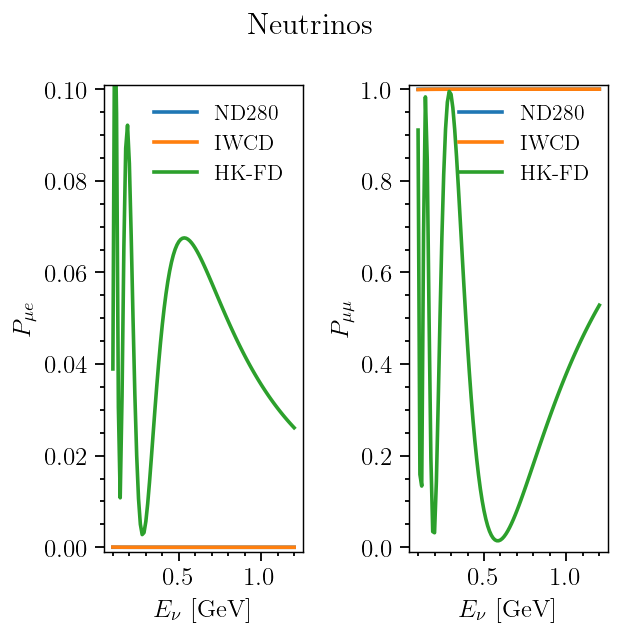

In [131]:
P_nu_mumu = {"ND280": np.zeros_like(Enu), "IWCD": np.zeros_like(Enu), "HK-FD": np.zeros_like(Enu)}
P_nu_mue = {"ND280": np.zeros_like(Enu), "IWCD": np.zeros_like(Enu), "HK-FD": np.zeros_like(Enu)}

ch = pychic.CHIC() # neutrino is default
for i, E in enumerate(Enu):
    # Take advantage of CHIC caching by looping over baselines inside the energy loop
    for det, L in detectors.items():
        P = ch.compute_oscillations(E, L)
        P_nu_mue[det][i] = P[0][1]
        P_nu_mumu[det][i] = P[1][1]
del ch

fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle("Neutrinos")
for det in detectors.keys():
    ax1.plot(Enu, P_nu_mue[det], label=det)
    ax1.legend()
    ax2.plot(Enu, P_nu_mumu[det], label=det)
    ax2.legend()
ax1.set(xlabel=r"$E_{\nu}$ [GeV]", ylabel=r"$P_{\mu e}$")
ax1.set_ylim([-0.001, 1.01e-1])
ax2.set(xlabel=r"$E_{\nu}$ [GeV]", ylabel=r"$P_{\mu \mu}$")
ax2.set_ylim([-0.01, 1.01])
plt.tight_layout()
plt.show()

And for antineutrinos, we have.

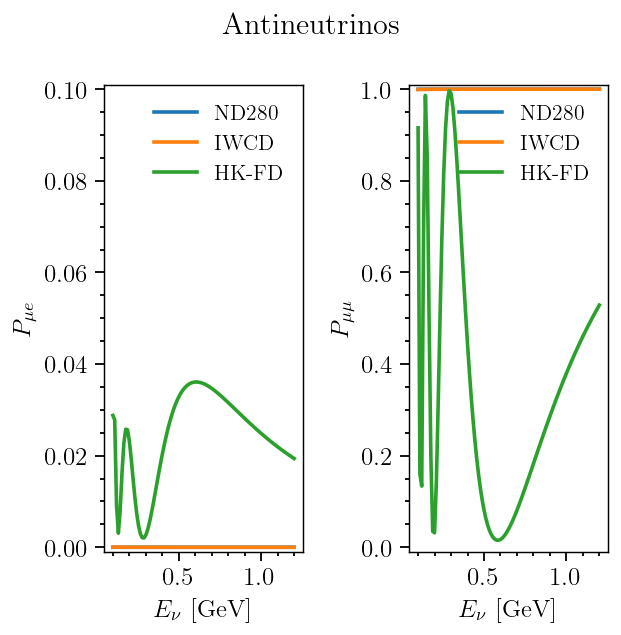

In [132]:
P_nu_mumu = {"ND280": np.zeros_like(Enu), "IWCD": np.zeros_like(Enu), "HK-FD": np.zeros_like(Enu)}
P_nu_mue = {"ND280": np.zeros_like(Enu), "IWCD": np.zeros_like(Enu), "HK-FD": np.zeros_like(Enu)}

ch = pychic.CHIC("antineutrino")
for i, E in enumerate(Enu):
    # Take advantage of CHIC caching by looping over baselines inside the energy loop
    for det, L in detectors.items():
        P = ch.compute_oscillations(E, L)
        P_nu_mue[det][i] = P[0][1]
        P_nu_mumu[det][i] = P[1][1]
del ch

fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle("Antineutrinos")
for det in detectors.keys():
    ax1.plot(Enu, P_nu_mue[det], label=det)
    ax1.legend()
    ax2.plot(Enu, P_nu_mumu[det], label=det)
    ax2.legend()
ax1.set(xlabel=r"$E_{\nu}$ [GeV]", ylabel=r"$P_{\mu e}$")
ax1.set_ylim([-0.001, 1.01e-1])
ax2.set(xlabel=r"$E_{\nu}$ [GeV]", ylabel=r"$P_{\mu \mu}$")
ax2.set_ylim([-0.01, 1.01])
plt.tight_layout()
plt.show()

## Oscillation probabilities from interpolation
Instead of computing many points to obtain the oscillation probability as function of neutrino energy, we could take advantage of the derivatives and interpolate from fewer points. For this case, we just show it for HK-FD.

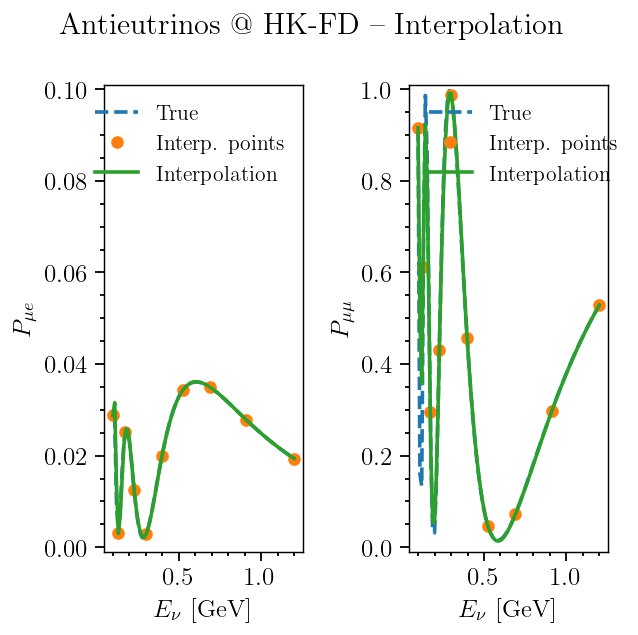

In [133]:
from scipy.interpolate import CubicHermiteSpline, CubicSpline

Enu_few = np.geomspace(0.1, 1.2, 10)
P_mumu = np.zeros_like(Enu_few)
P_mue = np.zeros_like(Enu_few)
dP_mumu = np.zeros_like(Enu_few)
dP_mue = np.zeros_like(Enu_few)

dch = pychic.CHICDIFF("antineutrino")
for i, E in enumerate(Enu_few):
    P = dch.compute_oscillations(E, detectors["HK-FD"])
    P_mue[i] = P[0][1]
    P_mumu[i] = P[1][1]
    dP = dch.compute_oscillations_derivatives("E", E, detectors["HK-FD"])
    dP_mue[i] = dP[0][1]
    dP_mumu[i] = dP[1][1]
del dch

fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle("Antieutrinos @ HK-FD -- Interpolation")

ax1.plot(Enu, P_nu_mue["HK-FD"], "--", label="True")
P_mue_interp = CubicHermiteSpline(Enu_few, P_mue, dP_mue)
ax1.plot(Enu_few, P_mue, "o", label="Interp. points")
ax1.plot(Enu, P_mue_interp(Enu), label="Interpolation")
ax1.legend()

ax2.plot(Enu, P_nu_mumu["HK-FD"], "--", label="True")
P_mumu_interp = CubicHermiteSpline(Enu_few, P_mumu, dP_mumu)
ax2.plot(Enu_few, P_mumu, "o", label="Interp. points")
ax2.plot(Enu, P_mumu_interp(Enu), label="Interpolation")
ax2.legend()

ax1.set(xlabel=r"$E_{\nu}$ [GeV]", ylabel=r"$P_{\mu e}$")
ax1.set_ylim([-0.001, 1.01e-1])
ax2.set(xlabel=r"$E_{\nu}$ [GeV]", ylabel=r"$P_{\mu \mu}$")
ax2.set_ylim([-0.01, 1.01])

plt.tight_layout()
plt.show()

The same can be done for any other parameter enetring the Hamiltonian. For instance in the case of the CP phase.

[]

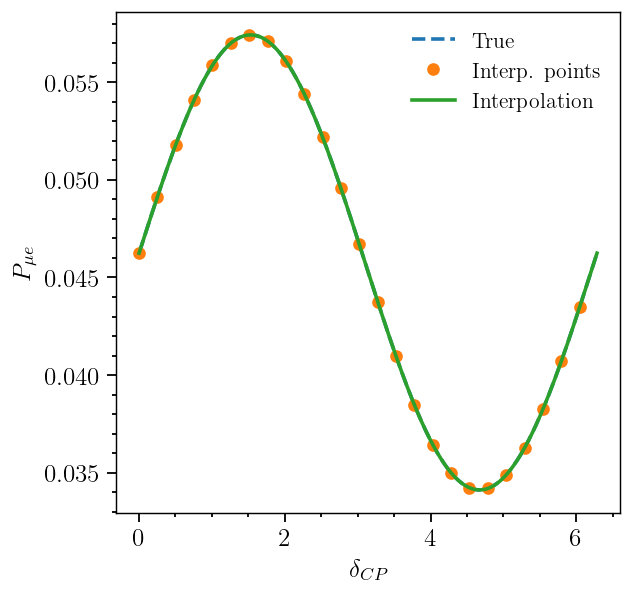

In [134]:
dcp = np.linspace(0, 2 * np.pi, 500)
P = np.zeros_like(dcp)
dP = np.zeros_like(dcp)

dch = pychic.CHICDIFF("antineutrino")

for i, r in enumerate(dcp):
    dch.update_dcp(r)
    Px = dch.compute_oscillations(0.6, 295.)
    dPx = dch.compute_oscillations_derivatives("dcp", 0.6, 295.)
    P[i] = Px[0][1]
    dP[i] = dPx[0][1]
del dch

# Select a subset of points to interpolate
dcp_subset = dcp[0::20]
P_subset = P[0::20]
dP_subset = dP[0::20]

interp = CubicHermiteSpline(dcp_subset, P_subset, dP_subset)
P_interp = interp(dcp)

# Plotting results
plt.plot(dcp, P, "--", label="True")
plt.plot(dcp_subset, P_subset, "o", label="Interp. points")
plt.plot(dcp, P_interp, label="Interpolation")
plt.ylabel(r"$P_{\mu e}$")
plt.xlabel(r"$\delta_{CP}$")
plt.legend()
plt.plot()

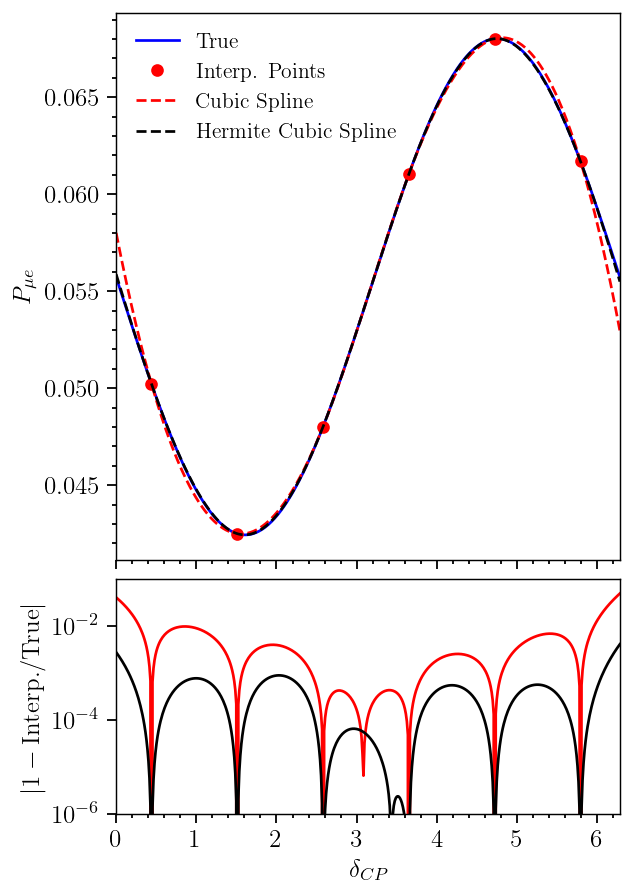

In [135]:
dcp = np.linspace(0, 2 * np.pi, 500)
P = np.zeros_like(dcp)
dP = np.zeros_like(dcp)

dch = pychic.CHICDIFF("neutrino")

for i, r in enumerate(dcp):
    dch.update_dcp(r)
    Px = dch.compute_oscillations(0.6, 295.)
    dPx = dch.compute_oscillations_derivatives("dcp", 0.6, 295.)
    P[i] = Px[0][1]
    dP[i] = dPx[0][1]
del dch

# Select a subset of points to interpolate
dcp_subset = dcp[35::85]
P_subset = P[35::85]
dP_subset = dP[35::85]

interp_h = CubicHermiteSpline(dcp_subset, P_subset, dP_subset)
P_interp_h = interp_h(dcp)

interp = CubicSpline(dcp_subset, P_subset)
P_interp = interp(dcp)


# ── Figure layout ────────────────────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(5, 8),
    sharex=True,
    gridspec_kw={'height_ratios': [3.5, 1.5], 'hspace': 0.05}
)

# ── Upper panel ──────────────────────────────────────────────────────────────
ax1.plot(dcp, P,    color='blue',  ls='-',  lw=1.5, label='True')
ax1.plot(dcp_subset, P_subset, "o",
            color='red',        label='Interp. Points')
ax1.plot(dcp, P_interp,   color='red',   ls='--', lw=1.5, label='Cubic Spline')
ax1.plot(dcp, P_interp_h, color='black', ls='--', lw=1.5, label='Hermite Cubic Spline')

ax1.set_ylabel(r'$P_{\mu e}$')
ax1.set_xlim(0, 2 * np.pi)
ax1.legend(loc='upper left')
ax1.tick_params(labelbottom=False)          # hide x tick labels on upper panel

# ── Lower panel (log scale residuals) ────────────────────────────────────────

ax2.plot(dcp, np.abs(1-P_interp/P),   color='red',   lw=1.5)
ax2.plot(dcp, np.abs(1-P_interp_h/P), color='black', lw=1.5)


ax2.set_ylabel(r'$|1 - \mathrm{Interp.}/\mathrm{True}|$')
ax2.set_xlabel(r'$\delta_{CP}$')
ax2.set_xlim(0, 2 * np.pi)
ax2.semilogy()
ax2.set_ylim(1e-6, 1e-1)

# ── Shared x ticks at 0–6 ────────────────────────────────────────────────────
ax2.set_xticks(range(0, 7))

plt.savefig('spline_comparison.pdf', bbox_inches='tight')
plt.show()

[]

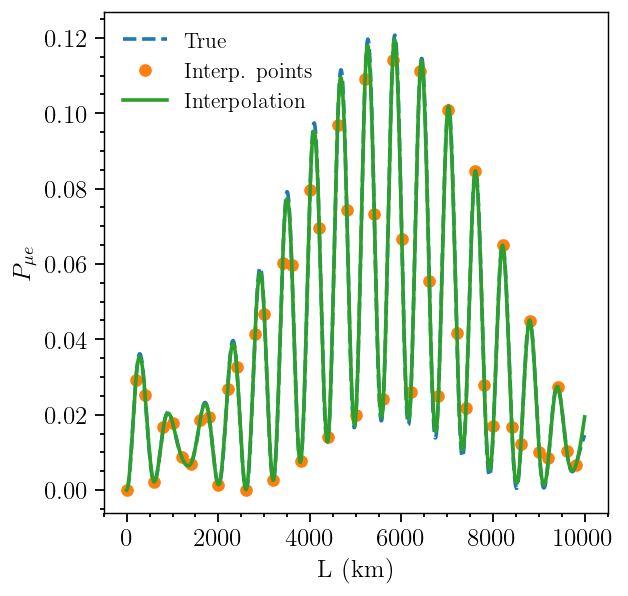

In [136]:
rho = np.linspace(0.0, 1e4, 1000)
P = np.zeros_like(rho)
dP = np.zeros_like(rho)

dch = pychic.CHICDIFF("antineutrino")

for i, r in enumerate(rho):
    # dch.update_th12(r)
    Px = dch.compute_oscillations(0.6, r)
    dPx = dch.compute_oscillations_derivatives("L", 0.6, r)
    P[i] = Px[0][1]
    dP[i] = dPx[0][1]
del dch

# Select a subset of points to interpolate
rho_subset = rho[0::20]
P_subset = P[0::20]
dP_subset = dP[0::20]

interp = CubicHermiteSpline(rho_subset, P_subset, dP_subset)
P_interp = interp(rho)

# Plotting results
plt.plot(rho, P, "--", label="True")
plt.plot(rho_subset, P_subset, "o", label="Interp. points")
plt.plot(rho, P_interp, label="Interpolation")
plt.ylabel(r"$P_{\mu e}$")
plt.xlabel(r"L (km)")
plt.legend()
plt.plot()

## Oscillograds
Now, we explore the oscillograds in combination with the usual oscillograms. These are 2-D plots of the oscillation probability (oscillogram) and its derivative with respect some parameter (oscillograds).

First, the appearance probability for HK-FD and it derivative with respect to the CP phase as a function of the CP phase and the square mass difference between the first and third mass eigenvalues (including both mass orderings).

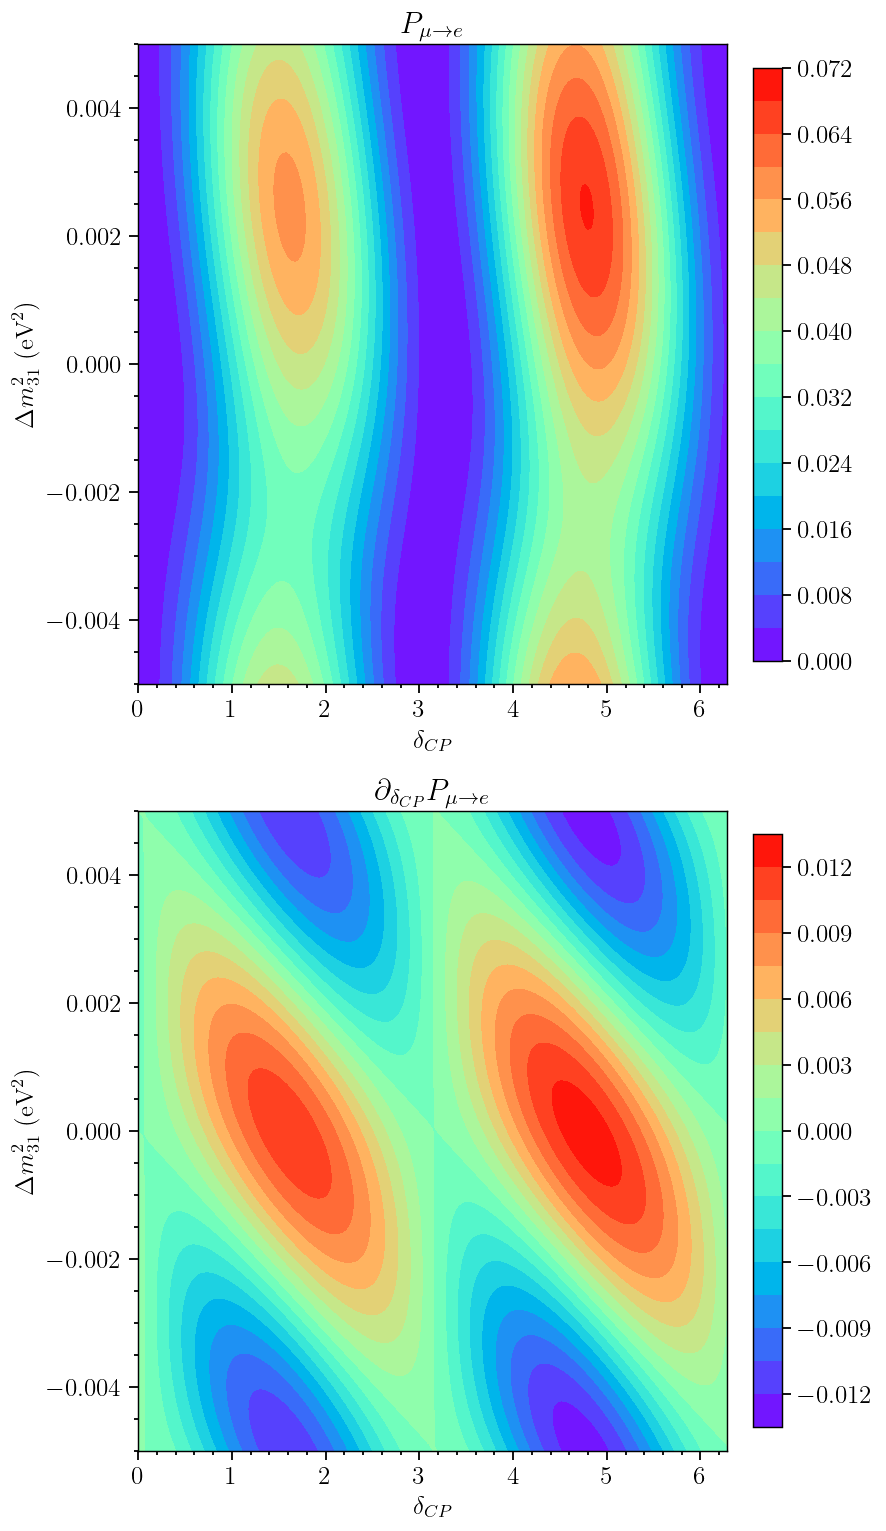

In [137]:
# grids
dm231 = np.linspace(-5e-3, 5e-3, 200)
dcp = np.linspace(0, np.pi*2, 200)
P = np.zeros((dcp.size, dm231.size))
dP = np.zeros((dcp.size, dm231.size))
levels = 20

dch = pychic.CHICDIFF()

# compute P(dcp, dm231)
for i, delta in enumerate(dcp): #x
    dch.update_dcp(delta)                   # update CP phase
    for j, dm in enumerate(dm231): #y
        dch.update_dm231(dm)                 # update dm231
        Px = dch.compute_oscillations(Enu_peak, detectors["HK-FD"])
        dPx = dch.compute_oscillations_derivatives("dcp", Enu_peak, detectors["HK-FD"])
        P[i, j] = Px[0, 1]
        dP[i, j] = dPx[0, 1]

del dch

fig, axes = plt.subplots(2, 1, figsize=(7, 12))

CP, DM = np.meshgrid(dcp, dm231)

# P panel
cs0 = axes[0].contourf(CP, DM, P, levels=levels, cmap='rainbow', extend='neither')
axes[0].set_ylabel(r'$\Delta m^2_{31}$~(eV$^2$)')
axes[0].set_xlabel(r'$\delta_{CP}$')
axes[0].set_title(r'$P_{\mu\rightarrow e}$')
cbar0 = fig.colorbar(cs0, ax=axes[0], fraction=0.046, pad=0.04)

# dP panel
cs1 = axes[1].contourf(CP, DM, dP, levels=levels, cmap='rainbow', extend='neither')
axes[1].set_ylabel(r'$\Delta m^2_{31}$~(eV$^2$)')
axes[1].set_xlabel(r'$\delta_{CP}$')
axes[1].set_title(r'$\partial_{\delta_{CP}}P_{\mu\rightarrow e}$')
cbar1 = fig.colorbar(cs1, ax=axes[1], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

The same can be done as a function of the CP phase and the 2-3 mixing angle.

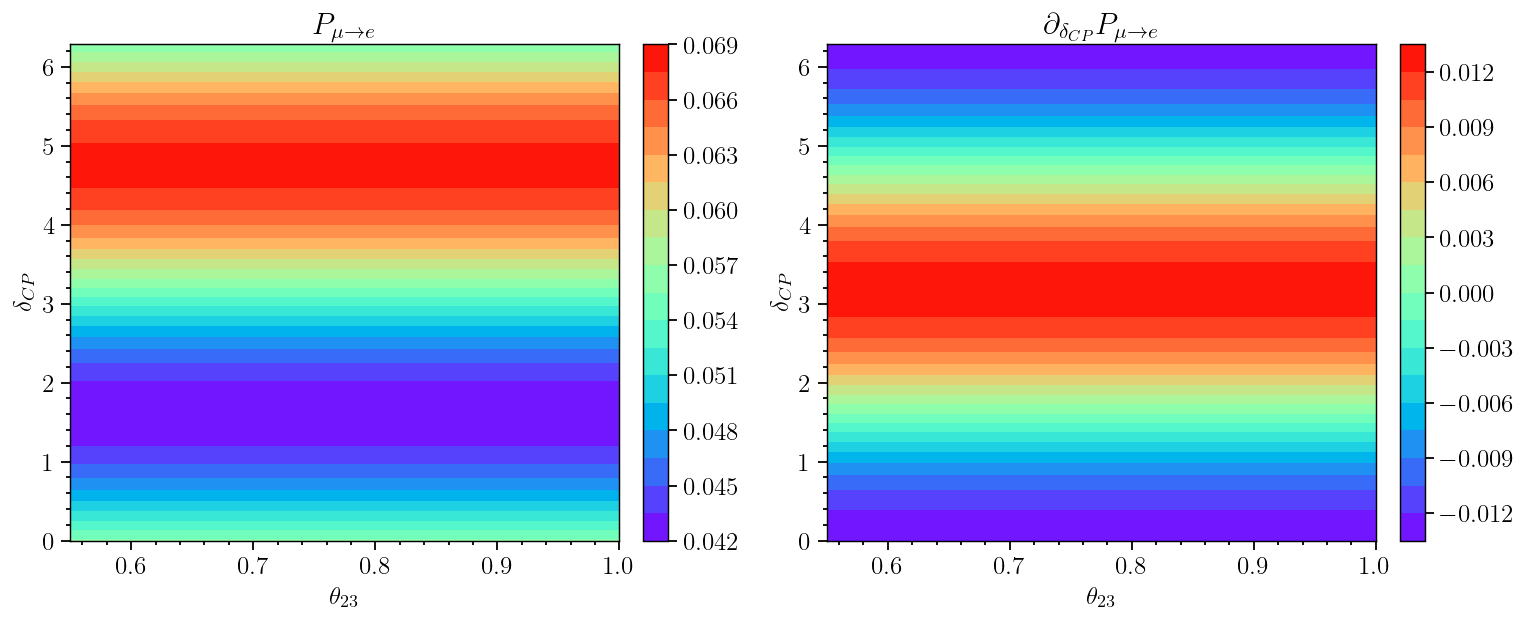

In [138]:
# grids
th23 = np.linspace(0.55, 1, 200)
P = np.zeros((dcp.size, dm231.size))
dP = np.zeros((dcp.size, dm231.size))
levels = 20

dch = pychic.CHICDIFF()

for i, delta in enumerate(dcp):
    dch.update_dcp(delta)                 # update theta23
    for j, delta in enumerate(th23):
        Px = dch.compute_oscillations(Enu_peak, detectors["HK-FD"])
        dPx = dch.compute_oscillations_derivatives("dcp", Enu_peak, detectors["HK-FD"])
        P[i, j] = Px[0, 1]
        dP[i, j] = dPx[0, 1]


fig, axes = plt.subplots(1, 2, figsize=(12, 5))

TH, CP = np.meshgrid(th23, dcp)

# P panel
cs0 = axes[0].contourf(TH, CP, P, levels=levels, cmap='rainbow', extend='neither')
axes[0].set_xlabel(r'$\theta_{23}$')
axes[0].set_ylabel(r'$\delta_{CP}$')
axes[0].set_title(r'$P_{\mu\rightarrow e}$')
cbar0 = fig.colorbar(cs0, ax=axes[0], fraction=0.046, pad=0.04)

# dP panel
cs1 = axes[1].contourf(TH, CP, dP, levels=levels, cmap='rainbow', extend='neither')
axes[1].set_xlabel(r'$\theta_{23}$')
axes[1].set_ylabel(r'$\delta_{CP}$')
axes[1].set_title(r'$\partial_{\delta_{CP}}P_{\mu\rightarrow e}$')
cbar1 = fig.colorbar(cs1, ax=axes[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

Finally, we reproduce the oscillograd for the CP phase in the energy range relevant to DUNE.

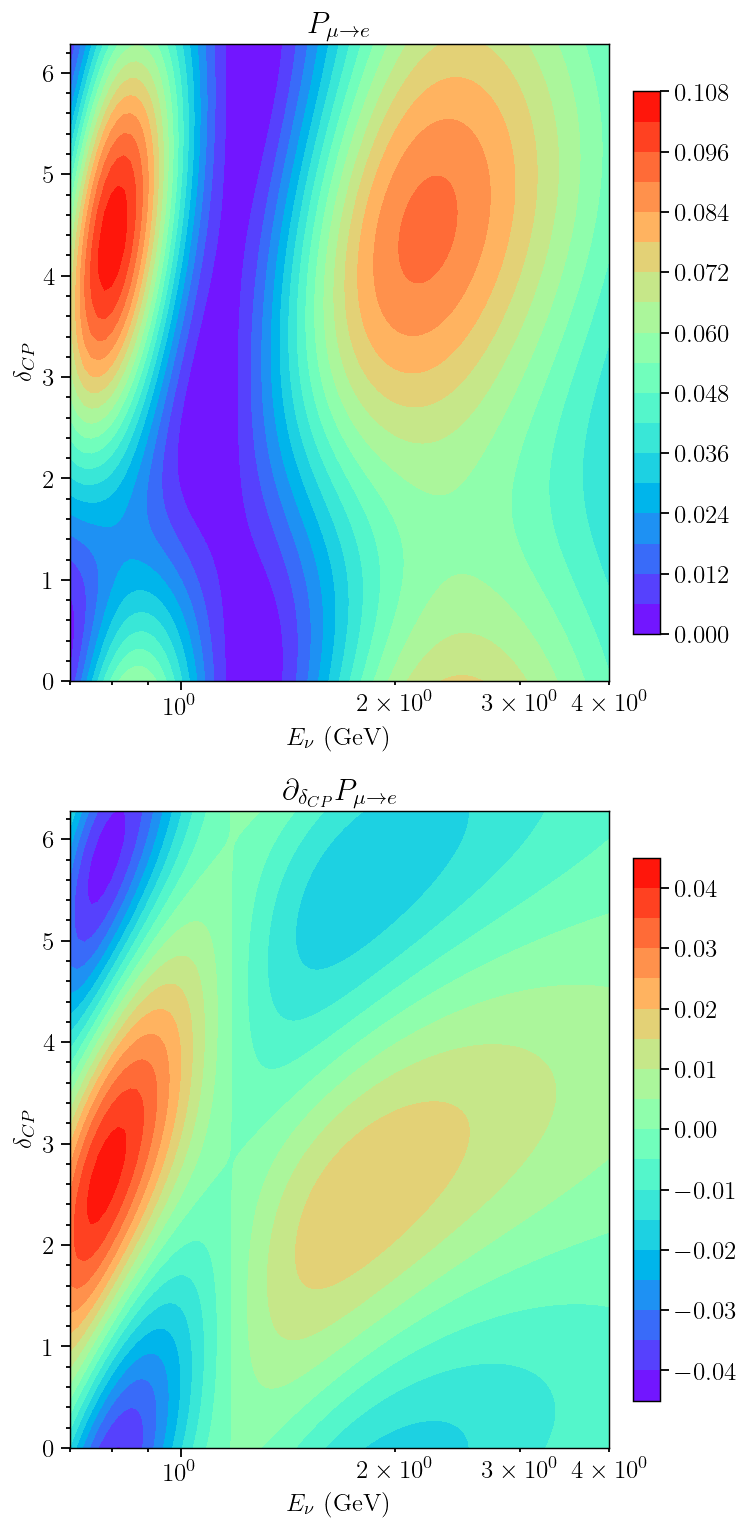

In [139]:
DUNE_energy = np.linspace(0.7, 4., 200)
DUNE_L = 1300. # km

for i, th in enumerate(dcp): # y
    dch.update_dcp(th)                 # update theta23
    for j, E_DUNE in enumerate(DUNE_energy): # x
        Px = dch.compute_oscillations(E_DUNE, DUNE_L)
        dPx = dch.compute_oscillations_derivatives("dcp", E_DUNE, DUNE_L)
        P[i, j] = Px[0, 1]
        dP[i, j] = dPx[0, 1]

fig, axes = plt.subplots(2, 1, figsize=(6, 12))

ED, CP = np.meshgrid(DUNE_energy, dcp)

# P panel
cs0 = axes[0].contourf(ED, CP, P, levels=levels, cmap='rainbow', extend='neither')
axes[0].set_xlabel(r'$E_\nu$ (GeV)')
axes[0].set_ylabel(r'$\delta_{CP}$')
axes[0].set_title(r'$P_{\mu\rightarrow e}$')
axes[0].semilogx()
cbar0 = fig.colorbar(cs0, ax=axes[0], fraction=0.046, pad=0.04)

# dP panel
cs1 = axes[1].contourf(ED, CP, dP, levels=levels, cmap='rainbow', extend='neither')
axes[1].set_xlabel(r'$E_\nu$ (GeV)')
axes[1].set_ylabel(r'$\delta_{CP}$')
axes[1].set_title(r'$\partial_{\delta_{CP}}P_{\mu\rightarrow e}$')
axes[1].semilogx()
cbar1 = fig.colorbar(cs1, ax=axes[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

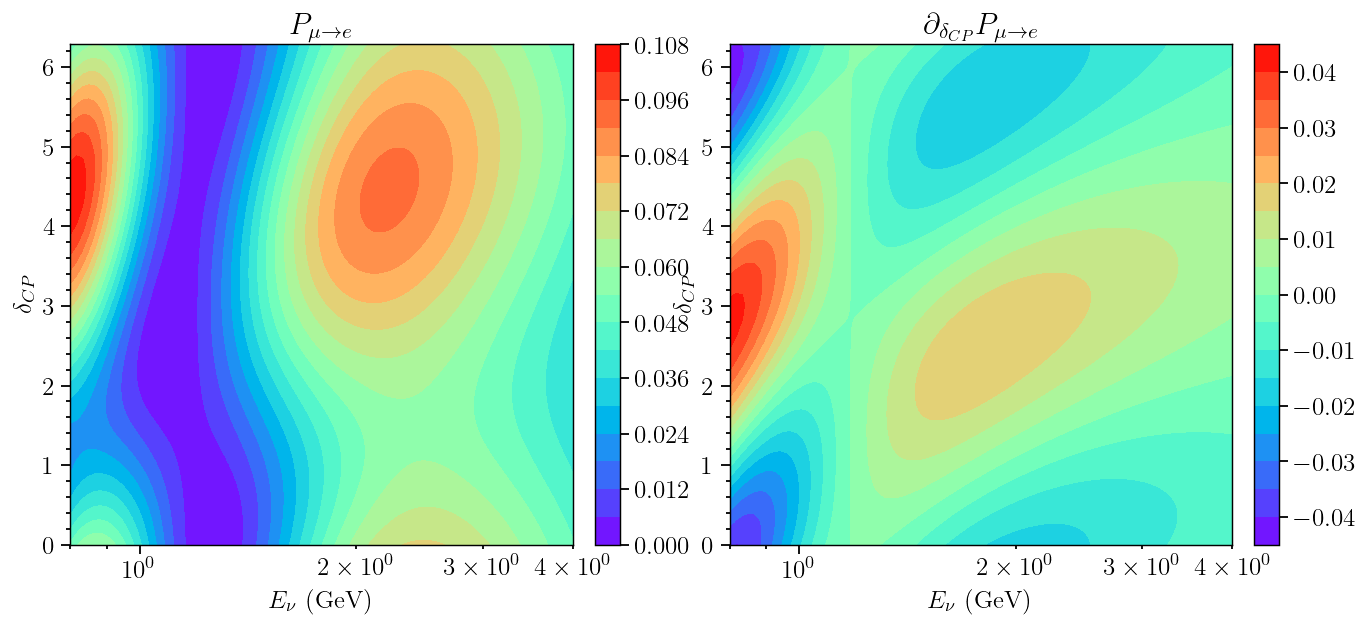

In [140]:
DUNE_energy = np.linspace(0.8, 4., 200)
DUNE_L = 1300. # km

for i, th in enumerate(dcp): # y
    dch.update_dcp(th)                 # update theta23
    for j, E_DUNE in enumerate(DUNE_energy): # x
        Px = dch.compute_oscillations(E_DUNE, DUNE_L)
        dPx = dch.compute_oscillations_derivatives("dcp", E_DUNE, DUNE_L)
        P[i, j] = Px[0, 1]
        dP[i, j] = dPx[0, 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ED, CP = np.meshgrid(DUNE_energy, dcp)

# P panel
cs0 = axes[0].contourf(ED, CP, P, levels=levels, cmap='rainbow', extend='neither')
axes[0].set_xlabel(r'$E_\nu$ (GeV)')
axes[0].set_ylabel(r'$\delta_{CP}$')
axes[0].set_title(r'$P_{\mu\rightarrow e}$')
axes[0].semilogx()
cbar0 = fig.colorbar(cs0, ax=axes[0], fraction=0.046, pad=0.04)

# dP panel
cs1 = axes[1].contourf(ED, CP, dP, levels=levels, cmap='rainbow', extend='neither')
axes[1].set_xlabel(r'$E_\nu$ (GeV)')
axes[1].set_ylabel(r'$\delta_{CP}$')
axes[1].set_title(r'$\partial_{\delta_{CP}}P_{\mu\rightarrow e}$')
axes[1].semilogx()
cbar1 = fig.colorbar(cs1, ax=axes[1], fraction=0.046, pad=0.04)

plt.show()

# Usage of CHICEARTH python module

Brief overview of how to run CHICEARTH to compute neutrino oscillation probabilities and their derivatives.
It assumes that CHIC python bindings have been compiled.

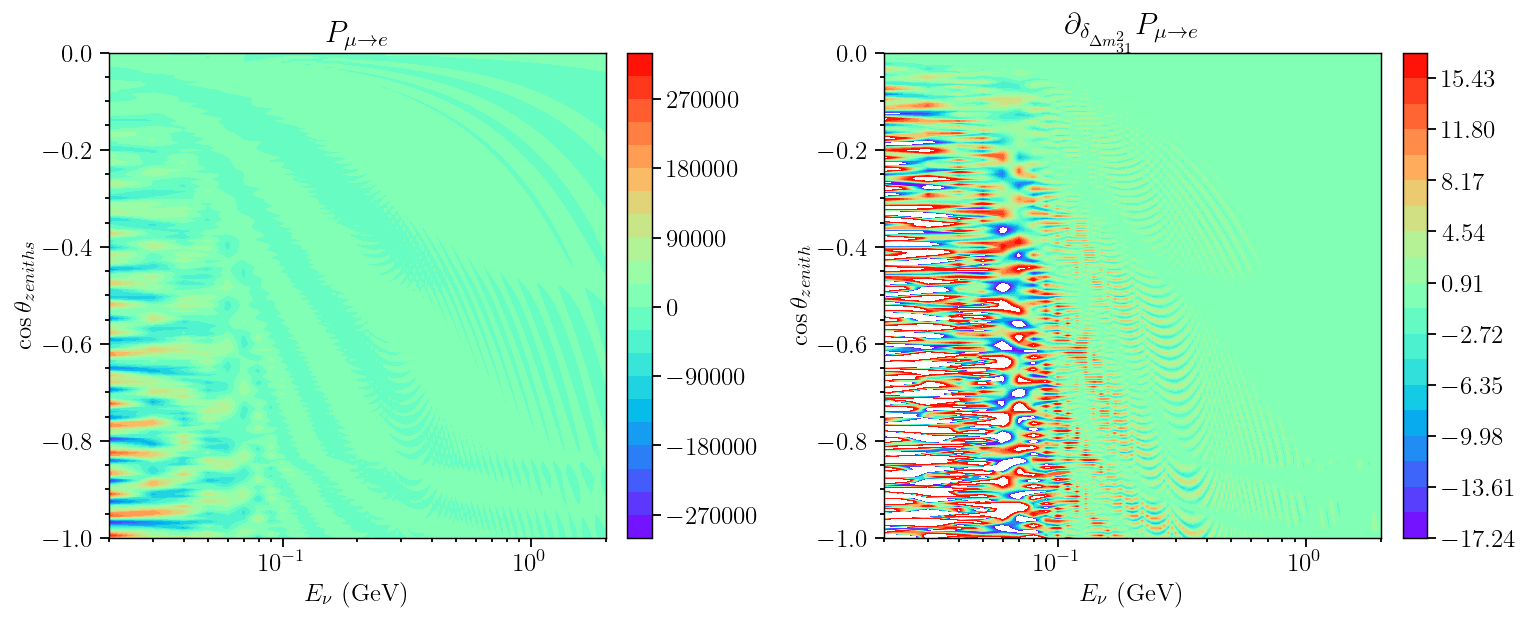

In [141]:
import pychic_earth as pe

energies = np.linspace(0.02, 2.0, 200)
zeniths = np.linspace(-1.0, 0.0, 200)
P = np.zeros((energies.size, zeniths.size))
dP = np.zeros((energies.size, zeniths.size))

# dch = pe.CHICEARTHDIFF(mode="neutrino")
dch = pe.CHICEARTHDIFF(mode="antineutrino")
dch.update_dm231(-2.44e-3)

for i, cz in enumerate(zeniths): # y
    for j, E in enumerate(energies): # x
        Px = dch.compute_oscillations(E, cz)
        dPx = dch.compute_oscillations_derivatives("dm221", E, cz)
        P[i, j] = dPx[0, 1]
        dPx = dch.compute_oscillations_derivatives("dm231", E, cz)
        dP[i, j] = dPx[0, 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ED, CZ = np.meshgrid(energies, zeniths)

# P panel
cs0 = axes[0].contourf(ED, CZ, P, levels=levels, cmap='rainbow', extend='neither')
axes[0].set_xlabel(r'$E_\nu$ (GeV)')
axes[0].set_ylabel(r'$\cos\theta_{zeniths}$')
axes[0].set_title(r'$P_{\mu\rightarrow e}$')
axes[0].semilogx()
cbar0 = fig.colorbar(cs0, ax=axes[0], fraction=0.046, pad=0.04)

# dP panel
dP = dP*1e-3
vmax = np.abs(dP).max()
levels1 = np.linspace(-np.abs(vmax)/10, np.abs(vmax)/10, 20)
cs1 = axes[1].contourf(ED, CZ, dP, levels=levels1, cmap='rainbow', extend='neither')
axes[1].set_xlabel(r'$E_\nu$ (GeV)')
axes[1].set_ylabel(r'$\cos\theta_{zenith}$')
axes[1].set_title(r'$\partial_{\delta_{\Delta m^2_{31}}}P_{\mu\rightarrow e}$')
axes[1].semilogx()
cbar1 = fig.colorbar(cs1, ax=axes[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

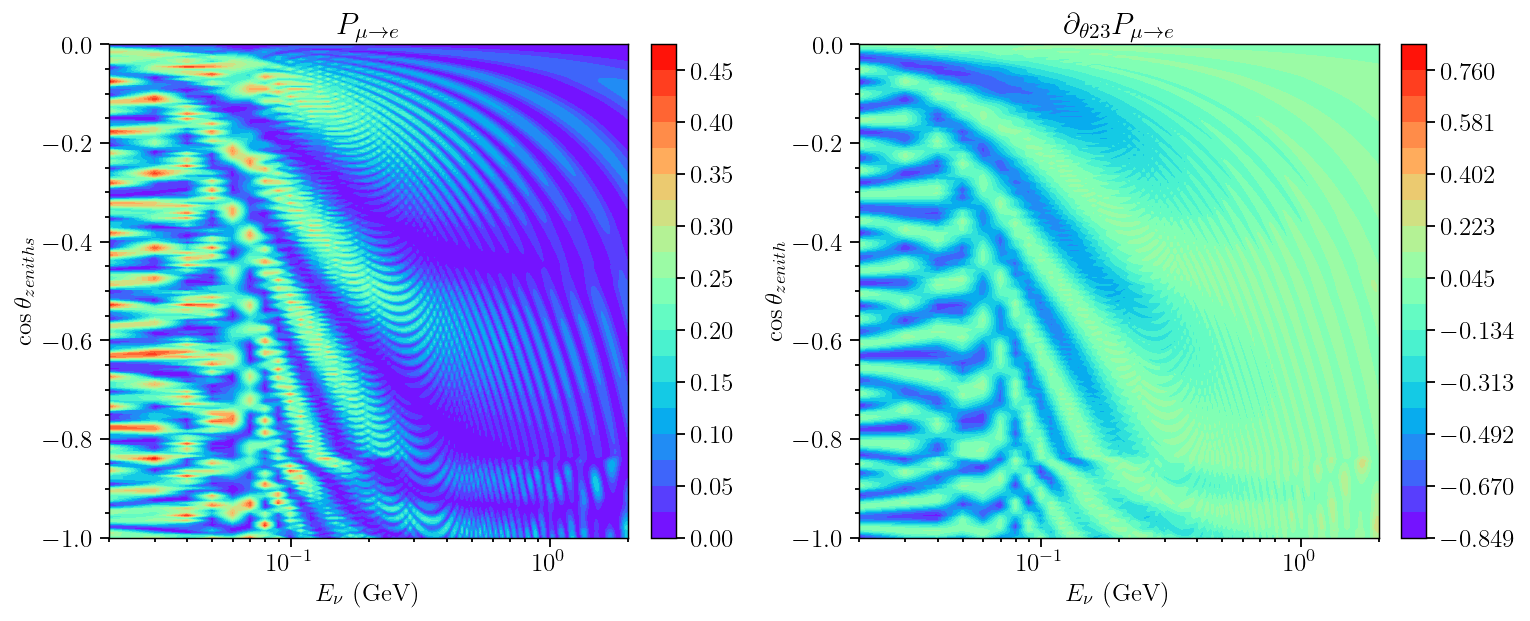

In [142]:
for i, cz in enumerate(zeniths): # y
    for j, E in enumerate(energies): # x
        Px = dch.compute_oscillations(E, cz)
        dPx = dch.compute_oscillations_derivatives("th23", E, cz)
        P[i, j] = Px[1, 0]
        dP[i, j] = dPx[1, 0]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ED, CZ = np.meshgrid(energies, zeniths)

# P panel
cs0 = axes[0].contourf(ED, CZ, P, levels=levels, cmap='rainbow', extend='neither')
axes[0].set_xlabel(r'$E_\nu$ (GeV)')
axes[0].set_ylabel(r'$\cos\theta_{zeniths}$')
axes[0].set_title(r'$P_{\mu\rightarrow e}$')
axes[0].semilogx()
cbar0 = fig.colorbar(cs0, ax=axes[0], fraction=0.046, pad=0.04)

# dP panel
dP = dP
vmax = np.abs(dP).max()
levels1 = np.linspace(-vmax, vmax, 20)
cs1 = axes[1].contourf(ED, CZ, dP, levels=levels1, cmap='rainbow', extend='neither')
axes[1].set_xlabel(r'$E_\nu$ (GeV)')
axes[1].set_ylabel(r'$\cos\theta_{zenith}$')
axes[1].set_title(r'$\partial_{{ \theta23}}P_{\mu\rightarrow e}$')
axes[1].semilogx()
cbar1 = fig.colorbar(cs1, ax=axes[1], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

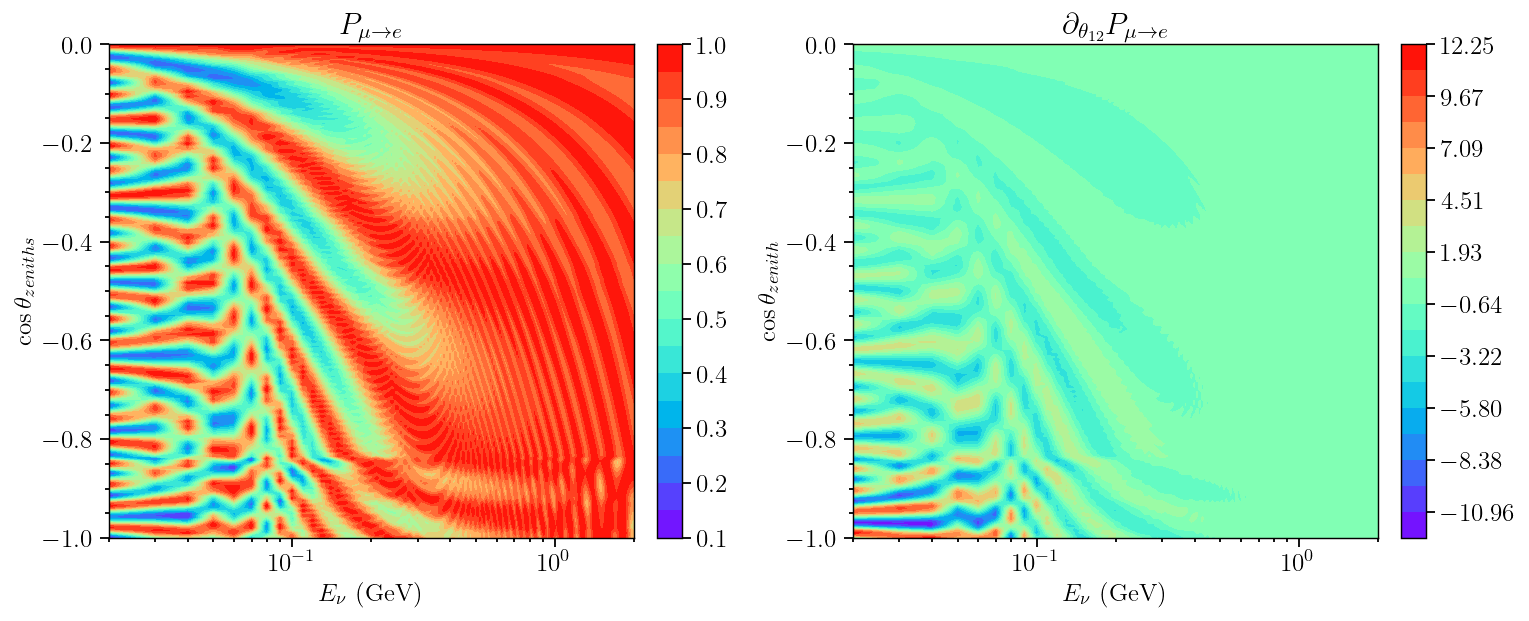

In [143]:
for i, cz in enumerate(zeniths): # y
    for j, E in enumerate(energies): # x
        Px = dch.compute_oscillations(E, cz)
        dPx = dch.compute_oscillations_derivatives("th12", E, cz)
        P[i, j] = Px[0, 0]
        dP[i, j] = dPx[0, 0]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ED, CZ = np.meshgrid(energies, zeniths)

# P panel
cs0 = axes[0].contourf(ED, CZ, P, levels=levels, cmap='rainbow', extend='neither')
axes[0].set_xlabel(r'$E_\nu$ (GeV)')
axes[0].set_ylabel(r'$\cos\theta_{zeniths}$')
axes[0].set_title(r'$P_{\mu\rightarrow e}$')
axes[0].semilogx()
cbar0 = fig.colorbar(cs0, ax=axes[0], fraction=0.046, pad=0.04)

# dP panel
dP = dP
vmax = np.abs(dP).max()
levels1 = np.linspace(-vmax, vmax, 20)
cs1 = axes[1].contourf(ED, CZ, dP, levels=levels1, cmap='rainbow', extend='neither')
axes[1].set_xlabel(r'$E_\nu$ (GeV)')
axes[1].set_ylabel(r'$\cos\theta_{zenith}$')
axes[1].set_title(r'$\partial_{{ \theta_{12}}}P_{\mu\rightarrow e}$')
axes[1].semilogx()
cbar1 = fig.colorbar(cs1, ax=axes[1], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

For more details, please check https://arxiv.org/abs/2512.16427.

# Check different approximations

/tmp/ipykernel_17035/851422682.py:151: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


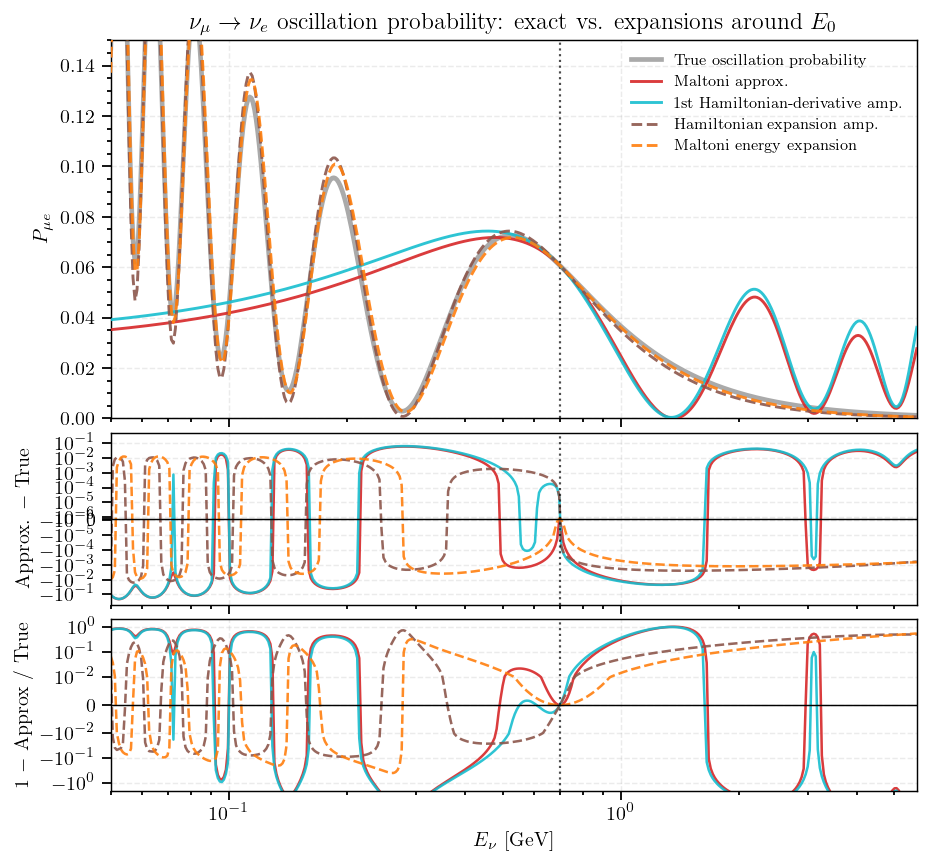

In [144]:
import pychic
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm, inv

# ----------------------------------------------------------------------
# Computation
# ----------------------------------------------------------------------
E0 = 0.7
dE = np.geomspace(E0 - 0.65, E0 + 5.0, 400)
P_malt_nu_mue = np.zeros(400)
P_malt_exp_nu_mue = np.zeros(400)
P_2malt_nu_mue = np.zeros(400)
P_cal_nu_mue = np.zeros(400)
P_1st_nu_mue = np.zeros(400)
P_1stu_nu_mue = np.zeros(400)
P_dH_nu_mue = np.zeros(400)
P_dHexp_nu_mue = np.zeros(400)
Enu = np.geomspace(E0 - 0.65, E0 + 5.0, 500)
P_nu_mue = np.zeros(500)

ch = pychic.CHICDIFF()  # neutrino is default
ch.update_density(5e0)
for i, E in enumerate(Enu):
    P = ch.compute_oscillations(E, 295.)
    P_nu_mue[i] = P[0][1]

__ = ch.compute_oscillations_derivatives("E", E0, 295.)
S_nu_mue = ch.get_amplitude()
dS_nu_mue = ch.get_diff_amplitude()
K = S_nu_mue.conj().T @ dS_nu_mue

# print("Conmutator:")
# Hv = ch.get_vacuum_hamiltonian()
# Hs = ch.get_hamiltonian()
# V = Hs - Hv
# print(cHv @ V - V @ Hv)

for i, E in enumerate(dE):
    S_maltoni = S_nu_mue @ expm(K * (E - E0))
    P_malt_nu_mue[i] = np.abs(S_maltoni)[0][1] ** 2

for i, E in enumerate(dE):
    S_maltoni = S_nu_mue @ expm(K * (E - E0) / (1+(E-E0)/E0))
    P_malt_exp_nu_mue[i] = np.abs(S_maltoni)[0][1] ** 2

for i, E in enumerate(dE):
    S_maltoni = expm(0.5 * K * (E - E0)) @ S_nu_mue @ expm(0.5 * K * (E - E0))
    P_2malt_nu_mue[i] = np.abs(S_maltoni)[0][1] ** 2

for i, E in enumerate(dE):
    S_caley = S_nu_mue @ inv(np.identity(3) - 0.5 * K * (E - E0)) @ (np.identity(3) + 0.5 * K * (E - E0))
    P_cal_nu_mue[i] = np.abs(S_caley)[0][1] ** 2

for i, E in enumerate(dE):
    S_1st = S_nu_mue + dS_nu_mue * (E - E0)
    P_1st_nu_mue[i] = np.abs(S_1st)[0][1] ** 2

for i, E in enumerate(dE):
    S_1st = S_nu_mue + dS_nu_mue * (E - E0)
    W, Sv, Vh = np.linalg.svd(S_1st)
    S_1st = W @ Vh
    P_1stu_nu_mue[i] = np.abs(S_1st)[0][1] ** 2

ch.update_density(0.0)
__ = ch.compute_oscillations(E0, 295.)
H = ch.get_hamiltonian()
for i, E in enumerate(dE):
    S_dH = expm(1j * (E - E0) / E0 * H * 5.067730716156394 * 295.)
    S_SdH = S_nu_mue @ S_dH
    P_dH_nu_mue[i] = np.abs(S_SdH)[0][1] ** 2

ch.update_density(0.0)
__ = ch.compute_oscillations(E0, 295.)
H = ch.get_hamiltonian()
for i, E in enumerate(dE):
    ch.compute_energy_expansion(E-E0)
    S_dH = ch.get_H_expE()
    # S_dH = expm(1j * (E - E0) / E * H * 5.067730716156394 * 295.)
    S_SdH = S_nu_mue @ S_dH
    P_dHexp_nu_mue[i] = np.abs(S_SdH)[0][1] ** 2

# ----------------------------------------------------------------------
# Visualization
# ----------------------------------------------------------------------
plt.rcParams.update({
    "figure.dpi": 130,
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "--",
    "legend.framealpha": 0.9,
})

curves = [
    (P_malt_nu_mue,   "Maltoni approx.",                    "#d62728", "-"),
    # (P_2malt_nu_mue,  "Two-sided Maltoni approx.",          "#9467bd", "--"),
    # (P_cal_nu_mue,    "Cayley map (Maltoni) approx.",       "#2ca02c", "-."),
    # (P_1st_nu_mue,    "First-order approx.",                "#ff7f0e", ":"),
    (P_dH_nu_mue,     "1st Hamiltonian-derivative amp.",    "#17becf", "-"),
    (P_dHexp_nu_mue,  "Hamiltonian expansion amp.",         "#8c564b", "--"),
    (P_malt_exp_nu_mue,  "Maltoni energy expansion",         "#ff7f0e", "--"),
]
# P_1stu_nu_mue (first-order unitary) kept available but left off, as in the original

fig, (ax_top, ax_res, ax_resr) = plt.subplots(
    3, 1, figsize=(8, 7.5), sharex=True,
    gridspec_kw={"height_ratios": [2.2, 1, 1], "hspace": 0.06},
)

# --- top panel: probabilities ---
ax_top.plot(Enu, P_nu_mue, color="#aaaaaa", lw=2.6, label="True oscillation probability", zorder=1)
for data, label, color, ls in curves:
    ax_top.plot(dE, data, color=color, ls=ls, lw=1.6, label=label, alpha=0.9, zorder=3)

ax_top.axvline(E0, color="black", ls=":", lw=1.2, alpha=0.7)
ax_top.annotate(
    "Reference point", xy=(E0, 0.47), xytext=(E0 + 0.012, 0.47),
    fontsize=9, va="center",
)
ax_top.set_ylabel(r"$P_{\mu e}$")
ax_top.set_ylim(0.0, 0.15)
ax_top.set_xlim(E0 - 0.65, E0 + 5.0)
ax_top.semilogx()
ax_top.legend(loc="upper right", fontsize=8.5, ncol=1)
ax_top.set_title(r"$\nu_\mu \to \nu_e$ oscillation probability: exact vs. expansions around $E_0$")

# --- bottom panel: residuals vs true probability (interpolated onto dE grid) ---
P_true_on_dE = np.interp(dE, Enu, P_nu_mue)
for data, label, color, ls in curves:
    ax_res.plot(dE, (data - P_true_on_dE), color=color, ls=ls, lw=1.4, alpha=0.9)
    ax_resr.plot(dE, (data - P_true_on_dE)/(1e-12 - P_true_on_dE), color=color, ls=ls, lw=1.4, alpha=0.9)

ax_resr.axhline(0.0, color="black", lw=0.8)
ax_resr.axvline(E0, color="black", ls=":", lw=1.2, alpha=0.7)
ax_resr.set_ylim(-2, 2)
ax_resr.semilogx()
ax_resr.set_yscale("symlog", linthresh=1e-2)
ax_resr.set_ylabel(r" 1 $-$ Approx / True")
ax_resr.set_xlabel(r"$E_{\nu}$ [GeV]")
ax_resr.set_xlim(E0 - 0.65, E0 + 5.0)
ax_res.axhline(0.0, color="black", lw=0.8)
ax_res.axvline(E0, color="black", ls=":", lw=1.2, alpha=0.7)
ax_res.set_yscale("symlog", linthresh=1e-5)
ax_res.set_ylim(-0.5, 0.5)
ax_res.set_ylabel(r"Approx. $-$ True")
ax_res.set_xlabel(r"$E_{\nu}$ [GeV]")
ax_res.set_xlim(E0 - 0.65, E0 + 5.0)
ax_res.semilogx()

plt.tight_layout()
plt.show()

/tmp/ipykernel_17035/1045736736.py:151: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


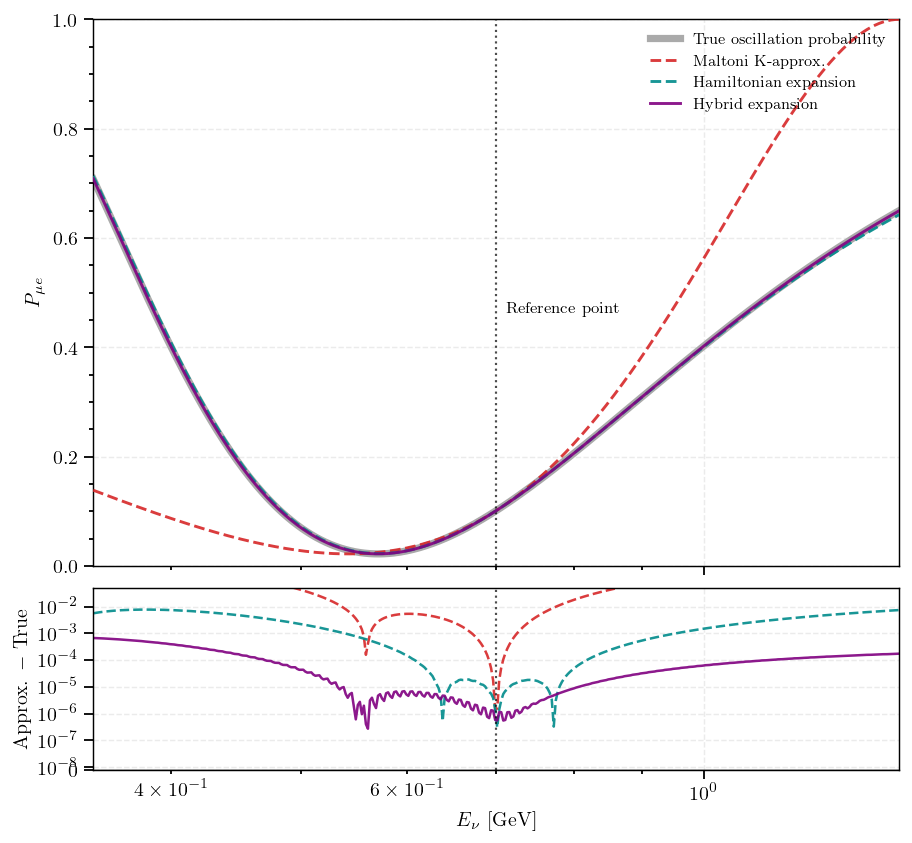

In [145]:
import pychic
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm, inv

# ----------------------------------------------------------------------
# Computation
# ----------------------------------------------------------------------
E0 = 0.7
dE = np.geomspace(0.5*E0, 2*E0, 400)
P_malt_nu_mue = np.zeros(400)
P_malt_exp_nu_mue = np.zeros(400)
P_2malt_nu_mue = np.zeros(400)
P_cal_nu_mue = np.zeros(400)
P_1st_nu_mue = np.zeros(400)
P_1stu_nu_mue = np.zeros(400)
P_dH_nu_mue = np.zeros(400)
P_dHexp_nu_mue = np.zeros(400)
Enu = np.geomspace(0.5*E0, 2*E0, 500)
P_nu_mue = np.zeros(500)

ch = pychic.CHICDIFF()  # neutrino is default
ch.update_density(2e3)
for i, E in enumerate(Enu):
    P = ch.compute_oscillations(E, 295.)
    P_nu_mue[i] = P[2][2]

__ = ch.compute_oscillations_derivatives("E", E0, 295.)
S_nu_mue = ch.get_amplitude()
dS_nu_mue = ch.get_diff_amplitude()
K = S_nu_mue.conj().T @ dS_nu_mue

# print("Conmutator:")
# Hv = ch.get_vacuum_hamiltonian()
# Hs = ch.get_hamiltonian()
# V = Hs - Hv
# print(cHv @ V - V @ Hv)

for i, E in enumerate(dE):
    S_maltoni = S_nu_mue @ expm(K * (E - E0))
    P_malt_nu_mue[i] = np.abs(S_maltoni)[2][2] ** 2

for i, E in enumerate(dE):
    S_maltoni = S_nu_mue @ expm(K * (E - E0) / (1+(E-E0)/E0))
    P_malt_exp_nu_mue[i] = np.abs(S_maltoni)[2][2] ** 2

for i, E in enumerate(dE):
    S_maltoni = expm(0.5 * K * (E - E0)) @ S_nu_mue @ expm(0.5 * K * (E - E0))
    P_2malt_nu_mue[i] = np.abs(S_maltoni)[2][2] ** 2

for i, E in enumerate(dE):
    S_caley = S_nu_mue @ inv(np.identity(3) - 0.5 * K * (E - E0)) @ (np.identity(3) + 0.5 * K * (E - E0))
    P_cal_nu_mue[i] = np.abs(S_caley)[2][2] ** 2

for i, E in enumerate(dE):
    S_1st = S_nu_mue + dS_nu_mue * (E - E0)
    P_1st_nu_mue[i] = np.abs(S_1st)[2][2] ** 2

for i, E in enumerate(dE):
    S_1st = S_nu_mue + dS_nu_mue * (E - E0)
    W, Sv, Vh = np.linalg.svd(S_1st)
    S_1st = W @ Vh
    P_1stu_nu_mue[i] = np.abs(S_1st)[2][2] ** 2

ch.update_density(0.0)
__ = ch.compute_oscillations(E0, 295.)
H = ch.get_hamiltonian()
for i, E in enumerate(dE):
    S_dH = expm(1j * (E - E0) / E0 * H * 5.067730716156394 * 295.)
    S_SdH = S_nu_mue @ S_dH
    P_dH_nu_mue[i] = np.abs(S_SdH)[2][2] ** 2

ch.update_density(0.0)
__ = ch.compute_oscillations(E0, 295.)
H = ch.get_hamiltonian()
for i, E in enumerate(dE):
    ch.compute_energy_expansion(E-E0)
    S_dH = ch.get_H_expE()
    # S_dH = expm(1j * (E - E0) / E * H * 5.067730716156394 * 295.)
    S_SdH = S_nu_mue @ S_dH
    P_dHexp_nu_mue[i] = np.abs(S_SdH)[2][2] ** 2

# ----------------------------------------------------------------------
# Visualization
# ----------------------------------------------------------------------
plt.rcParams.update({
    "figure.dpi": 130,
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "--",
    "legend.framealpha": 0.9,
})

curves = [
    (P_malt_nu_mue,   "Maltoni K-approx.",                    "#d62728", "--"),
    # (P_2malt_nu_mue,  "Two-sided Maltoni approx.",          "#9467bd", "--"),
    # (P_cal_nu_mue,    "Cayley map (Maltoni) approx.",       "#2ca02c", "-."),
    # (P_1st_nu_mue,    "First-order approx.",                "#ff7f0e", ":"),
    # (P_dH_nu_mue,     "1st Hamiltonian-derivative amp.",    "#17becf", "-"),
    (P_dHexp_nu_mue,  "Hamiltonian expansion",         "darkcyan", "--"),
    (P_malt_exp_nu_mue,  "Hybrid expansion",         "purple", "-"),
]
# P_1stu_nu_mue (first-order unitary) kept available but left off, as in the original

fig, (ax_top, ax_res) = plt.subplots(
    2, 1, figsize=(8, 7.5), sharex=True,
    gridspec_kw={"height_ratios": [3, 1], "hspace": 0.06},
)

# --- top panel: probabilities ---
ax_top.plot(Enu, P_nu_mue, color="#aaaaaa", lw=4, label="True oscillation probability", zorder=1)
for data, label, color, ls in curves:
    ax_top.plot(dE, data, color=color, ls=ls, lw=1.6, label=label, alpha=0.9, zorder=3)

ax_top.axvline(E0, color="black", ls=":", lw=1.2, alpha=0.7)
ax_top.annotate(
    "Reference point", xy=(E0, 0.47), xytext=(E0 + 0.012, 0.47),
    fontsize=9, va="center",
)
ax_top.set_ylabel(r"$P_{\mu e}$")
ax_top.set_ylim(0.0, 1.0)
ax_top.set_xlim(0.5*E0, 2*E0)
ax_top.semilogx()
ax_top.legend(loc="upper right", fontsize=8.5, ncol=1)
# ax_top.set_title(r"$\nu_\mu \to \nu_e$ oscillation probability: exact vs. expansions around $E=0.7~GeV$")

# --- bottom panel: residuals vs true probability (interpolated onto dE grid) ---
P_true_on_dE = np.interp(dE, Enu, P_nu_mue)
for data, label, color, ls in curves:
    ax_res.plot(dE, np.abs(data - P_true_on_dE), color=color, ls=ls, lw=1.4, alpha=0.9)
    # ax_resr.plot(dE, (data - P_true_on_dE)/(1e-12 - P_true_on_dE), color=color, ls=ls, lw=1.4, alpha=0.9)

# ax_resr.axhline(0.0, color="black", lw=0.8)
# ax_resr.axvline(E0, color="black", ls=":", lw=1.2, alpha=0.7)
# ax_resr.set_ylim(-2, 2)
# ax_resr.semilogx()
# ax_resr.set_yscale("symlog", linthresh=1e-2)
# ax_resr.set_ylabel(r" 1 $-$ Approx / True")
# ax_resr.set_xlabel(r"$E_{\nu}$ [GeV]")
# ax_resr.set_xlim(0.5*E0, 2*E0)
ax_res.axhline(0.0, color="black", lw=0.8)
ax_res.axvline(E0, color="black", ls=":", lw=1.2, alpha=0.7)
ax_res.set_yscale("symlog", linthresh=1e-7)
ax_res.set_ylim(0.0, 0.05)
ax_res.set_ylabel(r"Approx. $-$ True")
ax_res.set_xlabel(r"$E_{\nu}$ [GeV]")
ax_res.set_xlim(0.5*E0, 2*E0)
ax_res.semilogx()

plt.tight_layout()
plt.show()

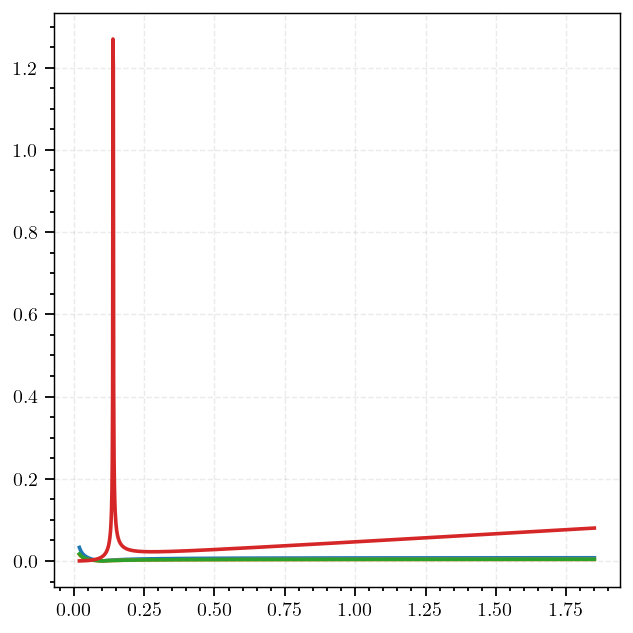

In [146]:
import pychic
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm, inv

# ----------------------------------------------------------------------
# Computation
# ----------------------------------------------------------------------
E0 = 0.1
dE = np.linspace(E0 - 0.08, E0 + 1.75, 500)
eigenvalue0 = np.zeros(500)
eigenvalue1 = np.zeros(500)
eigenvalue2 = np.zeros(500)

Enu = np.geomspace(E0 - 0.08, E0 + 1.75, 500)
P_nu_mue = np.zeros(500)

ch = pychic.CHICDIFF()  # neutrino is default
P = ch.compute_oscillations(E0, 295.)
lambdas = ch.get_eigenvalues()
eigenvalue00 = lambdas[0]
eigenvalue10 = lambdas[1]
eigenvalue20 = lambdas[2]

for i, E in enumerate(Enu):
    P = ch.compute_oscillations(E, 295.)
    lambdas = ch.get_eigenvalues()
    eigenvalue0[i] = lambdas[0]
    eigenvalue1[i] = lambdas[1]
    eigenvalue2[i] = lambdas[2]
    P_nu_mue[i] = P[0][1]

plt.plot(Enu, np.abs(eigenvalue00-eigenvalue0), label="True eigenvalue difference")
plt.plot(Enu, np.abs(eigenvalue10-eigenvalue1), label="True eigenvalue difference")
plt.plot(Enu, np.abs(eigenvalue20-eigenvalue2), label="True eigenvalue difference")
plt.plot(Enu, np.abs(0.0001*Enu**2/(0.0001-2.5e-3*(Enu-E0))), label="True eigenvalue difference")

plt.tight_layout()
plt.show()

0.05 0.000382888
0.0507687 0.000388774
0.0515492 0.000394751
0.0523418 0.00040082
0.0531465 0.000406983
0.0539636 0.00041324
0.0547932 0.000419593
0.0556356 0.000426044
0.0564909 0.000432594
0.0573594 0.000439244
0.0573594 0.000881853
0.0586873 0.000449413
0.0586873 0.000902267
0.0600459 0.000459817
0.0600459 0.000923154
0.0614359 0.000470461
0.0614359 0.000944525
0.0628581 0.000481352
0.0628581 0.00096639
0.0643133 0.000492495
0.0643133 0.000988762
0.0658021 0.000503896
0.0658021 0.00101165
0.0673254 0.000515561
0.0673254 0.00103507
0.068884 0.000527496
0.068884 0.00105903
0.0704786 0.000539708
0.0704786 0.00108355
0.0721102 0.000552202
0.0721102 0.00110863
0.0737795 0.000564985
0.0737795 0.0011343
0.0754875 0.000578064
0.0754875 0.00116056
0.077235 0.000591446
0.077235 0.00118742
0.0790229 0.000605138
0.0790229 0.00121491
0.0808523 0.000619147
0.0808523 0.00124303
0.082724 0.00063348
0.082724 0.00127181
0.084639 0.000648145
0.084639 0.00130125
0.0865984 0.000663149
0.0865984 0.001331

/tmp/ipykernel_17035/3946868876.py:55: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


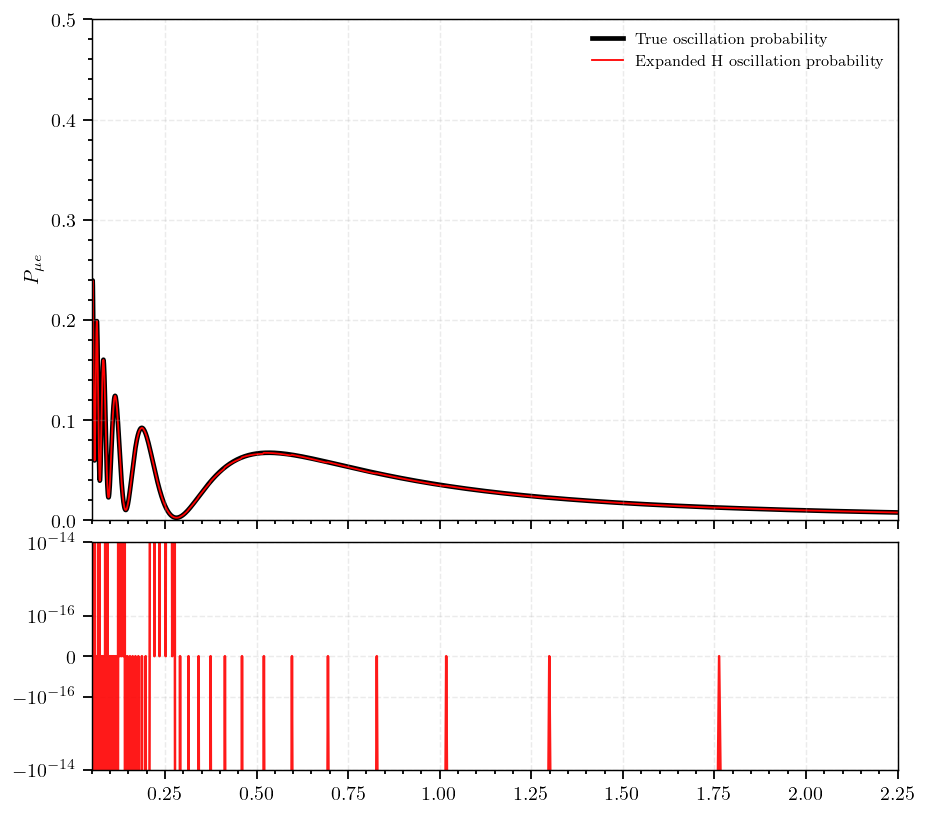

In [147]:
import pychic
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm, inv

# ----------------------------------------------------------------------
# Computation
# ----------------------------------------------------------------------
E0 = 0.5
Enu = np.geomspace(E0 - 0.45, E0 + 1.75, 500)
P_nu_mue = np.zeros(500)
Pexp_nu_mue = np.zeros(500)

ch = pychic.CHIC()  # neutrino is default
for i, E in enumerate(Enu):
    P = ch.compute_oscillations(E, 295.)
    P_nu_mue[i] = P[0][1]
for i, E in enumerate(Enu):
    P = ch.compute_oscillations_wexp(E, 295.)
    Pexp_nu_mue[i] = P[0][1]

# ----------------------------------------------------------------------
# Visualization
# ----------------------------------------------------------------------
plt.rcParams.update({
    "figure.dpi": 130,
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "--",
    "legend.framealpha": 0.9,
})


fig, (ax_top, ax_res) = plt.subplots(
    2, 1, figsize=(8, 7.5), sharex=True,
    gridspec_kw={"height_ratios": [2.2, 1], "hspace": 0.06},
)

# --- top panel: probabilities ---
ax_top.plot(Enu, P_nu_mue, color="black", lw=2.6, label="True oscillation probability", zorder=1)
ax_top.plot(Enu, Pexp_nu_mue, color="red", lw=1, label="Expanded H oscillation probability", zorder=1)

ax_top.set_ylabel(r"$P_{\mu e}$")
ax_top.set_ylim(0.0, 0.5)
ax_top.set_xlim(E0 - 0.45, E0 + 1.75)
ax_top.legend(loc="upper right", fontsize=8.5, ncol=1)

# --- bottom panel: residuals vs true probability (interpolated onto dE grid) ---
ax_res.plot(Enu, (Pexp_nu_mue - P_nu_mue), color="red", lw=1.4, alpha=0.9)
ax_res.set_ylim(-1e-14, 1e-14)
ax_res.set_xlim(E0 - 0.45, E0 + 1.75)
ax_res.set_yscale("symlog", linthresh=1e-16)

plt.tight_layout()
plt.show()

IndexError: boolean index did not match indexed array along dimension 0; dimension is 400 but corresponding boolean dimension is 500

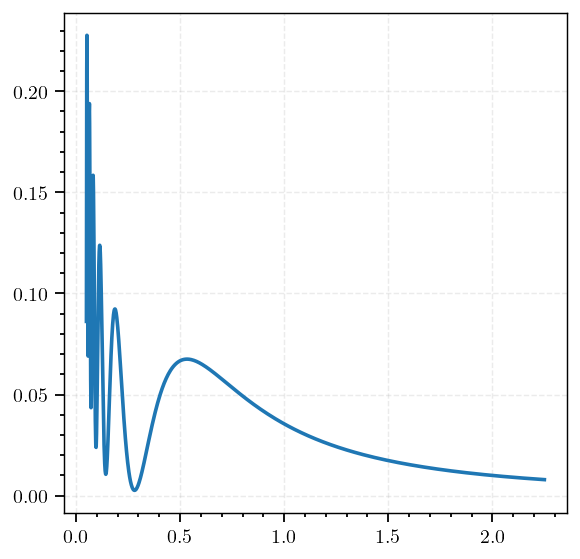

In [148]:
import numpy as np

def bin_average_interp(x, y, dx, kind='cubic'):
    """
    Average y in bins of width dx, then interpolate back onto
    the original x grid so output has the same size as input.
    
    kind: 'linear' or 'cubic' (cubic gives smoother curves,
          but can overshoot near sharp features)
    """
    bins = np.arange(x.min(), x.max() + dx, dx)
    bin_idx = np.digitize(x, bins) - 1

    x_centers = []
    y_avg = []

    for i in range(len(bins) - 1):
        mask = bin_idx == i
        if mask.any():
            x_centers.append(x[mask].mean())
            y_avg.append(y[mask].mean())

    x_centers = np.array(x_centers)
    y_avg = np.array(y_avg)

    if kind == 'linear':
        y_smooth = np.interp(x, x_centers, y_avg)
    else:
        from scipy.interpolate import interp1d
        f = interp1d(x_centers, y_avg, kind=kind,
                     bounds_error=False, fill_value='extrapolate')
        y_smooth = f(x)

    return y_smooth  # same size as x, y

dx_avg = 3e-3

y_smooth = bin_average_interp(Enu, P_nu_mue, dx=dx_avg)
plt.plot(Enu, y_smooth, label="True Osc. Proability")
y_smooth = bin_average_interp(dE, P_malt_nu_mue, dx=dx_avg)
plt.plot(dE, y_smooth, label="Maltoni Approx.")
y_smooth = bin_average_interp(dE, P_cal_nu_mue, dx=dx_avg)
plt.plot(dE, y_smooth, label="Caley map for Maltoni Approx.")
y_smooth = bin_average_interp(dE, P_1st_nu_mue, dx=dx_avg)
plt.plot(dE, y_smooth, label="First order approx.")
y_smooth = bin_average_interp(dE, P_dH_nu_mue, dx=dx_avg)
plt.plot(dE, y_smooth, label="Amplitude of Hamiltonian derivative")
y_smooth = bin_average_interp(dE, P_dHexp_nu_mue, dx=dx_avg)
plt.plot(dE, y_smooth, label="Amplitude of Hamiltonian expansion")
plt.vlines(E0, 0.0, 0.25, colors="black", linestyles="dashed", label="Reference point")
plt.ylim(0.0, 0.5)
plt.xlim(0.02, 0.08)
plt.legend()
plt.show()

In [ ]:
import pychic_earth
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm, inv

# ----------------------------------------------------------------------
# Computation
# ----------------------------------------------------------------------
E0 = 0.07
dE = np.linspace(E0 - 0.04, E0 + 0.1, 400)
P_malt_nu_mue = np.zeros(400)
P_2malt_nu_mue = np.zeros(400)
P_cal_nu_mue = np.zeros(400)
P_1st_nu_mue = np.zeros(400)
P_1stu_nu_mue = np.zeros(400)
P_dH_nu_mue = np.zeros(400)
P_dHexp_nu_mue = np.zeros(400)
Enu = np.geomspace(0.01, 0.15, 500)
P_nu_mue = np.zeros(500)

ch = pychic_earth.CHICEARTHDIFF()  # neutrino is default
for i, E in enumerate(Enu):
    P = ch.compute_oscillations(E, -0.9)
    P_nu_mue[i] = P[0][1]

__ = ch.compute_oscillations_derivatives("E", E0, -0.9)
S_nu_mue = ch.get_amplitude()
dS_nu_mue = ch.get_diff_amplitude()
K = S_nu_mue.conj().T @ dS_nu_mue

for i, E in enumerate(dE):
    S_maltoni = S_nu_mue @ expm(K * (E - E0))
    P_malt_nu_mue[i] = np.abs(S_maltoni)[0][1] ** 2

for i, E in enumerate(dE):
    S_maltoni = S_nu_mue @ expm(K * (E - E0)/E*E0)
    P_2malt_nu_mue[i] = np.abs(S_maltoni)[0][1] ** 2

for i, E in enumerate(dE):
    S_caley = S_nu_mue @ inv(np.identity(3) - 0.5 * K * (E - E0)) @ (np.identity(3) + 0.5 * K * (E - E0))
    P_cal_nu_mue[i] = np.abs(S_caley)[0][1] ** 2

for i, E in enumerate(dE):
    S_1st = S_nu_mue + dS_nu_mue * (E - E0)
    P_1st_nu_mue[i] = np.abs(S_1st)[0][1] ** 2

for i, E in enumerate(dE):
    S_1st = S_nu_mue + dS_nu_mue * (E - E0)
    W, Sv, Vh = np.linalg.svd(S_1st)
    S_1st = W @ Vh
    P_1stu_nu_mue[i] = np.abs(S_1st)[0][1] ** 2

__ = ch.compute_oscillations(E0, -0.9)
H = ch.get_vacuum_hamiltonian()
L = ch.get_full_baseline()
print(H)
print(L)
for i, E in enumerate(dE):
    S_dH = expm(1j * (E - E0) / E0 * H * 5.067730716156394 * L)
    S_SdH = S_nu_mue @ S_dH
    P_dH_nu_mue[i] = np.abs(S_SdH)[0][1] ** 2

# __ = ch.compute_oscillations(E0, -0.9)
# __ = ch.compute_oscillations_derivatives("E", E0, -0.9)
# dH = ch.get_vacuum_hamiltonian()
for i, E in enumerate(dE):
    S_dH = expm(1j * (E - E0) / E * H * 5.067730716156394 * L)
    S_SdH = S_nu_mue @ S_dH
    P_dHexp_nu_mue[i] = np.abs(S_SdH)[0][1] ** 2

# ----------------------------------------------------------------------
# Visualization
# ----------------------------------------------------------------------
plt.rcParams.update({
    "figure.dpi": 130,
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "--",
    "legend.framealpha": 0.9,
})

curves = [
    (P_malt_nu_mue,   "Maltoni approx.",                    "#d62728", "-"),
    (P_2malt_nu_mue,  "Maltoni all orders approx." ,        "#9467bd", "--"),
    # (P_cal_nu_mue,    "Cayley map (Maltoni) approx.",       "#2ca02c", "-."),
    # (P_1st_nu_mue,    "First-order approx.",                "#ff7f0e", ":"),
    # (P_dH_nu_mue,     "1st Hamiltonian-derivative amp.",    "#17becf", "-"),
    (P_dHexp_nu_mue,  "Hamiltonian expansion amp.",         "#8c564b", "--"),
]
# P_1stu_nu_mue (first-order unitary) kept available but left off, as in the original

fig, (ax_top, ax_res, ax_resr) = plt.subplots(
    3, 1, figsize=(8, 7.5), sharex=True,
    gridspec_kw={"height_ratios": [2.2, 1, 1], "hspace": 0.06},
)

# --- top panel: probabilities ---
ax_top.plot(Enu, P_nu_mue, color="black", lw=2.6, label="True oscillation probability", zorder=1)
for data, label, color, ls in curves:
    ax_top.plot(dE, data, color=color, ls=ls, lw=1.6, label=label, alpha=0.9, zorder=3)

ax_top.axvline(E0, color="black", ls=":", lw=1.2, alpha=0.7)
ax_top.annotate(
    "Reference point", xy=(E0, 0.47), xytext=(E0 + 0.012, 0.47),
    fontsize=9, va="center",
)
ax_top.set_ylabel(r"$P_{\mu e}$")
ax_top.set_ylim(0.0, 1)
ax_top.set_xlim(0.01, 0.15)
ax_top.legend(loc="upper right", fontsize=8.5, ncol=1)
ax_top.set_title(r"$\nu_\mu \to \nu_e$ oscillation probability: exact vs. expansions around $E_0$")

# --- bottom panel: residuals vs true probability (interpolated onto dE grid) ---
P_true_on_dE = np.interp(dE, Enu, P_nu_mue)
for data, label, color, ls in curves:
    ax_res.plot(dE, (data - P_true_on_dE), color=color, ls=ls, lw=1.4, alpha=0.9)
    ax_resr.plot(dE, (data - P_true_on_dE)/(1e-12 - P_true_on_dE), color=color, ls=ls, lw=1.4, alpha=0.9)

ax_resr.axhline(0.0, color="black", lw=0.8)
ax_resr.axvline(E0, color="black", ls=":", lw=1.2, alpha=0.7)
ax_resr.set_ylim(-2, 2)
ax_resr.set_yscale("symlog", linthresh=10e-2)
ax_resr.set_ylabel(r" 1 $-$ Approx / True")
ax_resr.set_xlabel(r"$E_{\nu}$ [GeV]")
ax_resr.set_xlim(0.01, 0.15)
ax_res.axhline(0.0, color="black", lw=0.8)
ax_res.axvline(E0, color="black", ls=":", lw=1.2, alpha=0.7)
ax_res.set_yscale("symlog", linthresh=10e-2)
ax_res.set_ylim(-1, 1)
ax_res.set_ylabel(r"Approx. $-$ True")
ax_res.set_xlabel(r"$E_{\nu}$ [GeV]")
ax_res.set_xlim(0.01, 0.15)

plt.tight_layout()
plt.show()

‖[H0,Ha]‖ = 4.646782465310394


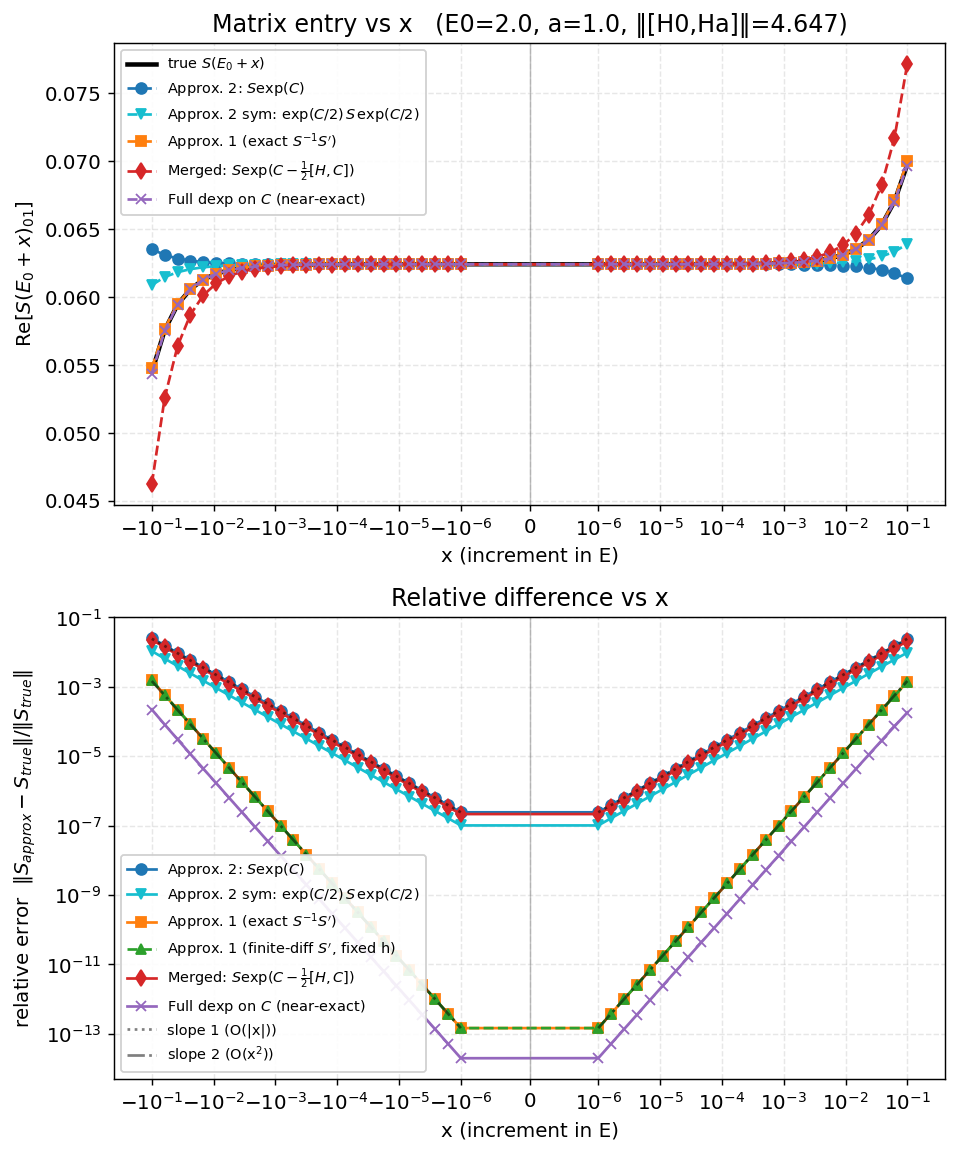

Approx2              err(x_min)=2.419e-07  local slope near x_min=1.00
Approx2_sym          err(x_min)=1.013e-07  local slope near x_min=1.00
Approx1_analytic     err(x_min)=1.469e-13  local slope near x_min=2.00
Approx1_findiff      err(x_min)=1.468e-13  local slope near x_min=2.00
Merged               err(x_min)=2.153e-07  local slope near x_min=1.00
Merged_full          err(x_min)=1.999e-14  local slope near x_min=2.00


In [ ]:
import numpy as np
from scipy.linalg import expm
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

# ---------------------------------------------------------------
# Build a random skew-Hermitian H(E) = H0 + Ha / E^a, with H0, Ha
# NOT commuting.
# ---------------------------------------------------------------
n = 4          # matrix size
a = 1.0        # power in H_a / E^a

def random_skew_hermitian(n, rng):
    A = rng.normal(size=(n, n)) + 1j * rng.normal(size=(n, n))
    return (A - A.conj().T) / 2

H0 = random_skew_hermitian(n, rng)
Ha = random_skew_hermitian(n, rng)

comm_H0_Ha = H0 @ Ha - Ha @ H0
print("‖[H0,Ha]‖ =", np.linalg.norm(comm_H0_Ha))

def H(E):
    return H0 + Ha / E**a

def Hprime(E):
    return -a * Ha / E**(a + 1)

def S(E):
    return expm(H(E))

def comm(A, B):
    return A @ B - B @ A

def phi_ad_H(H_mat, X):
    """
    Apply varphi(ad_H)(X) = X - 1/2[H,X] + 1/6[H,[H,X]] - ...,  varphi(z)=(1-e^{-z})/z,
    EXACTLY (no series truncation) by building the (n^2 x n^2) superoperator
    for ad_H acting on vec(X) and applying the scalar function phi via
    eigendecomposition. ad_H can have eigenvalues of order ~O(1) or larger,
    so a low-order truncated commutator series (as one might first try) can
    fail to converge -- this is exactly the kind of numerical trap that can
    masquerade as one approximation "beating" another.
    """
    n_ = H_mat.shape[0]
    I_ = np.eye(n_)
    # vec convention: vec(A X B) = (B^T kron A) vec(X)
    L_ad = np.kron(I_, H_mat) - np.kron(H_mat.T, I_)  # ad_H superoperator
    w, V = np.linalg.eig(L_ad)
    Vinv = np.linalg.inv(V)
    phi_w = np.where(np.abs(w) < 1e-10, 1.0 - w/2 + w**2/6, (1 - np.exp(-w)) / w)
    vecX = X.reshape(-1, order='F')
    result_vec = V @ (phi_w * (Vinv @ vecX))
    return result_vec.reshape(n_, n_, order='F')

def Sprime_exact(E, dE=None):
    """
    Exact S'(E) via the Frechet derivative of expm at H(E) in direction H'(E),
    computed with the standard 2n x 2n block-matrix trick:
        expm([[H, H'],[0, H]]) = [[S, S'],[0, S]]
    This avoids both (a) truncating the ad_H series and (b) the catastrophic
    cancellation of naive finite-differencing of S itself.
    """
    Hm = H(E)
    Hp = Hprime(E)
    n_ = Hm.shape[0]
    block = np.zeros((2 * n_, 2 * n_), dtype=complex)
    block[:n_, :n_] = Hm
    block[:n_, n_:] = Hp
    block[n_:, n_:] = Hm
    Eblock = expm(block)
    return Eblock[:n_, n_:]

def Hpp(E):
    return a * (a + 1) * Ha / E**(a + 2)

def B_of_s(s, E):
    """B(s) = varphi(ad_{H(E+s)})(H'(E+s)) -- the exact log-derivative of S at E+s.
    Smooth, well-conditioned function of s (no exponentials involved), so it is
    safe to differentiate numerically."""
    return phi_ad_H(H(E + s), Hprime(E + s))

def magnus_coeffs(E, h=1e-3):
    """
    Y1 = B0, Y2 = B0'/2, Y3 = B0''/6 + [B0,B0']/12
    B0', B0'' obtained by central finite differences of the smooth B(s).
    """
    Bm = B_of_s(-h, E)
    B0 = B_of_s(0.0, E)
    Bp = B_of_s(+h, E)
    B0p = (Bp - Bm) / (2 * h)             # B'(0)
    B0pp = (Bp - 2 * B0 + Bm) / h**2       # B''(0)

    Y1 = B0
    Y2 = 0.5 * B0p
    Y3 = B0pp / 6.0 + comm(B0, B0p) / 12.0
    return Y1, Y2, Y3

# ---------------------------------------------------------------
# Reference point E0 and sweep of small increments x
# ---------------------------------------------------------------
E0 = 2.0
xs_pos = np.logspace(-6, -1, 25)
xs = np.concatenate([-xs_pos[::-1], xs_pos])

err_approx1_analytic = []   # S exp(S^{-1}S' x), S^{-1}S' via exact Frechet-derivative trick
err_approx1_findiff   = []  # S exp(S^{-1}S' x), S' via naive finite differencing of S
err_approx2           = []  # S exp(C), C = H(E+x)-H(E)
err_approx2_sym       = []  # exp(C/2) S exp(C/2)  (symmetrized / Strang-split Approx. 2)
err_merged            = []  # S exp(C - 1/2[H,C])   (first commutator correction)
err_merged_full       = []  # S exp(varphi(ad_H)(C)) (full dexp series applied to C)

# track one representative matrix entry S[i,j] itself (real part) vs x,
# for the true S and for each approximation, to visualize convergence of
# the matrices themselves alongside the relative-error plot
i_track, j_track = 0, 1
S_true_entry            = []
S_approx1_analytic_entry = []
S_approx2_entry          = []
S_approx2_sym_entry      = []
S_merged_entry           = []
S_merged_full_entry      = []

H_E0 = H(E0)
S_E0 = S(E0)

for x in xs:
    S_true = S(E0 + x)

    # ---- Approximation 1, EXACT S' via Frechet-derivative block trick ----
    Sprime_exact_val = Sprime_exact(E0)
    SinvSprime_analytic = np.linalg.solve(S_E0, Sprime_exact_val)
    S_approx1_analytic = S_E0 @ expm(SinvSprime_analytic * x)

    # ---- Approximation 1, naive finite-difference S' ----
    # deliberately using a *fixed* small step h for the FD derivative,
    # independent of the outer x, to illustrate cancellation error
    h = 1e-6
    Sprime_fd = (S(E0 + h) - S(E0 - h)) / (2 * h)
    SinvSprime_fd = np.linalg.solve(S_E0, Sprime_fd)  # S^{-1} S'
    S_approx1_findiff = S_E0 @ expm(SinvSprime_fd * x)

    # ---- Approximation 2: raw exp(C) ----
    C = H(E0 + x) - H(E0)
    S_approx2 = S_E0 @ expm(C)

    # ---- Approximation 2, symmetrized (Strang split): exp(C/2) S exp(C/2) ----
    expC2 = expm(C / 2)
    S_approx2_sym = expC2 @ S_E0 @ expC2

    # ---- Merged, first commutator correction ----
    Omega_merged = C - 0.5 * comm(H_E0, C)
    S_merged = S_E0 @ expm(Omega_merged)

    # ---- Merged, full dexp series applied to C (near-exact) ----
    Omega_full = phi_ad_H(H_E0, C)
    S_merged_full = S_E0 @ expm(Omega_full)

    def relerr(S_approx):
        return np.linalg.norm(S_approx - S_true) / np.linalg.norm(S_true)

    err_approx1_analytic.append(relerr(S_approx1_analytic))
    err_approx1_findiff.append(relerr(S_approx1_findiff))
    err_approx2.append(relerr(S_approx2))
    err_approx2_sym.append(relerr(S_approx2_sym))
    err_merged.append(relerr(S_merged))
    err_merged_full.append(relerr(S_merged_full))

    S_true_entry.append(S_true[i_track, j_track].real)
    S_approx1_analytic_entry.append(S_approx1_analytic[i_track, j_track].real)
    S_approx2_entry.append(S_approx2[i_track, j_track].real)
    S_approx2_sym_entry.append(S_approx2_sym[i_track, j_track].real)
    S_merged_entry.append(S_merged[i_track, j_track].real)
    S_merged_full_entry.append(S_merged_full[i_track, j_track].real)

err_approx1_analytic = np.array(err_approx1_analytic)
err_approx1_findiff = np.array(err_approx1_findiff)
err_approx2 = np.array(err_approx2)
err_approx2_sym = np.array(err_approx2_sym)
err_merged = np.array(err_merged)
err_merged_full = np.array(err_merged_full)

# ---------------------------------------------------------------
# Two-panel plot: (top) the S matrix entry itself vs x,
#                 (bottom) relative difference vs x (log-log)
# ---------------------------------------------------------------
fig, (ax_top, ax_bot) = plt.subplots(2, 1, figsize=(7.5, 9))

colors = {
    'approx2': 'tab:blue',
    'approx2_sym': 'tab:cyan',
    'approx1_an': 'tab:orange',
    'approx1_fd': 'tab:green',
    'merged': 'tab:red',
    'merged_full': 'tab:purple',
}

# --- Top panel: Re[S(E0+x)_{i_track,j_track}] vs x, true vs approximations ---
ax_top.plot(xs, S_true_entry, 'k-', lw=2.5, label='true $S(E_0+x)$')
ax_top.plot(xs, S_approx2_entry, 'o--', color=colors['approx2'], label='Approx. 2: $S\\exp(C)$')
ax_top.plot(xs, S_approx2_sym_entry, 'v--', color=colors['approx2_sym'], label='Approx. 2 sym: $\\exp(C/2)\\,S\\,\\exp(C/2)$')
ax_top.plot(xs, S_approx1_analytic_entry, 's--', color=colors['approx1_an'], label='Approx. 1 (exact $S^{-1}S\'$)')
ax_top.plot(xs, S_merged_entry, 'd--', color=colors['merged'], label='Merged: $S\\exp(C-\\frac{1}{2}[H,C])$')
ax_top.plot(xs, S_merged_full_entry, 'x--', color=colors['merged_full'], label='Full dexp on $C$ (near-exact)')
ax_top.set_xscale('symlog', linthresh=1e-6)
ax_top.set_xlabel('x (increment in E)')
ax_top.set_ylabel(f'Re[$S(E_0+x)_{{{i_track}{j_track}}}$]')
ax_top.set_title(f'Matrix entry vs x   (E0={E0}, a={a}, ‖[H0,Ha]‖={np.linalg.norm(comm_H0_Ha):.3f})')
ax_top.legend(fontsize=8)
ax_top.grid(True, which='both', alpha=0.3)
ax_top.axvline(0, color='gray', lw=0.8, alpha=0.5)

# --- Bottom panel: relative error vs x, symlog-x / log-y ---
ax_bot.plot(xs, err_approx2, 'o-', color=colors['approx2'], label='Approx. 2: $S\\exp(C)$')
ax_bot.plot(xs, err_approx2_sym, 'v-', color=colors['approx2_sym'], label='Approx. 2 sym: $\\exp(C/2)\\,S\\,\\exp(C/2)$')
ax_bot.plot(xs, err_approx1_analytic, 's-', color=colors['approx1_an'], label='Approx. 1 (exact $S^{-1}S\'$)')
ax_bot.plot(xs, err_approx1_findiff, '^--', color=colors['approx1_fd'], label='Approx. 1 (finite-diff $S\'$, fixed h)')
ax_bot.plot(xs, err_merged, 'd-', color=colors['merged'], label='Merged: $S\\exp(C-\\frac{1}{2}[H,C])$')
ax_bot.plot(xs, err_merged_full, 'x-', color=colors['merged_full'], label='Full dexp on $C$ (near-exact)')

# reference slopes, plotted vs |x| on each side separately
xs_pos_ref = xs[xs > 0]
xs_neg_ref = xs[xs < 0]
slope1_pos = xs_pos_ref / xs_pos_ref[0] * err_approx2[xs > 0][0]
slope2_pos = (xs_pos_ref / xs_pos_ref[0])**2 * err_approx1_analytic[xs > 0][0]
ax_bot.plot(xs_pos_ref, slope1_pos, 'k:', alpha=0.5, label='slope 1 (O(|x|))')
ax_bot.plot(xs_pos_ref, slope2_pos, 'k-.', alpha=0.5, label='slope 2 (O(x$^2$))')
slope1_neg = np.abs(xs_neg_ref) / np.abs(xs_neg_ref[-1]) * err_approx2[xs < 0][-1]
slope2_neg = (np.abs(xs_neg_ref) / np.abs(xs_neg_ref[-1]))**2 * err_approx1_analytic[xs < 0][-1]
ax_bot.plot(xs_neg_ref, slope1_neg, 'k:', alpha=0.5)
ax_bot.plot(xs_neg_ref, slope2_neg, 'k-.', alpha=0.5)

ax_bot.set_xscale('symlog', linthresh=1e-6)
ax_bot.set_yscale('log')
ax_bot.set_xlabel('x (increment in E)')
ax_bot.set_ylabel('relative error  $\\|S_{approx}-S_{true}\\| / \\|S_{true}\\|$')
ax_bot.set_title('Relative difference vs x')
ax_bot.legend(fontsize=8)
ax_bot.grid(True, which='both', alpha=0.3)
ax_bot.axvline(0, color='gray', lw=0.8, alpha=0.5)

plt.tight_layout()
plt.show()

for name, err in [('Approx2', err_approx2),
                   ('Approx2_sym', err_approx2_sym),
                   ('Approx1_analytic', err_approx1_analytic),
                   ('Approx1_findiff', err_approx1_findiff),
                   ('Merged', err_merged),
                   ('Merged_full', err_merged_full)]:
    e = np.array(err)
    # local slope near the smallest |x|, using the positive-x branch
    ep = e[xs > 0]
    xp = xs[xs > 0]
    slope = np.log(ep[1] / ep[0]) / np.log(xp[1] / xp[0])
    print(f"{name:20s} err(x_min)={ep[0]:.3e}  local slope near x_min={slope:.2f}")